In [1]:
!pip install simpy

In [2]:
import simpy
import numpy as np
import random
import scipy.stats as st
import matplotlib.pyplot as plt
from scipy.stats import norm
import pandas as pd

# ==========================================
# הגדרת פרמטרים גלובליים
# ==========================================

np.random.seed(42)
random.seed(42)

SIM_TIME_HOURS = 12 # 12 שעות פעילות (07:00 עד 19:00)
SIM_TIME = SIM_TIME_HOURS * 60  # אופק הזמן של הסימולציה (בדקות)


# קצבי הגעה לפי שעות ביום
HOURLY_RATES = {
    (0, 3): 40.0,   # 07:00 - 10:00
    (3, 7): 80.0,   # 10:00 - 14:00
    (7, 9): 40.0,   # 14:00 - 16:00
    (9, 12): 100.0   # 16:00 - 19:00
}

# קצב מקסימלי עבור שיטת הדילול
MAX_LAMBDA_PER_HOUR = max(HOURLY_RATES.values())
MAX_LAMBDA_PER_MIN = max(HOURLY_RATES.values()) / 60.0  

# הסתברות לכמות תרופות בהזמנה
ORDER_SIZE_PROBS = {
    1: 0.3,
    2: 0.5,
    3: 0.2
}

# פרמטרי זמני ליקוט (התפלגות נורמלית קטומה)
PICK_TIME_MEAN = 0.5
PICK_TIME_STD = 0.1
PICK_TIME_MIN = 0.2

# זמן נסיעה למסדרון
travel_time_min = 0.2
travel_time_max = 0.4

# פרמטרי פריקת סחורה
SUPPLY_EVENTS_MINUTES = [60, 300]  # 08:00 (אחרי שעה) ו-12:00 (אחרי 5 שעות)
SUPPLY_MIN_BOXES = 40
SUPPLY_MAX_BOXES = 70
base_setup_time = 5.0    # זמן בסיסי של הגעת משאית והתארגנות    
time_per_item = PICK_TIME_MEAN     # כמה זמן לוקח לפרוק כל יחידת סחורה

# קיבולת משאבים
NUM_ROBOTS = 4
NUM_AISLES = 3

accept_prob = 1 - norm.cdf(
    PICK_TIME_MIN,
    loc=PICK_TIME_MEAN,
    scale=PICK_TIME_STD
)

if accept_prob < 1e-6:
    raise ValueError(
        "Acceptance probability is too small"
    )

# ווידוא הכנסת פרמטרים חוקיים
assert abs(sum(ORDER_SIZE_PROBS.values()) - 1) < 1e-9
assert PICK_TIME_STD > 0
assert travel_time_max > travel_time_min
assert SUPPLY_MAX_BOXES >= SUPPLY_MIN_BOXES
assert NUM_ROBOTS >= 1
assert NUM_AISLES >= 1

In [3]:
# ==========================================
# פונקציות התפלגות ומידול קלט
# ==========================================

def get_current_lambda(env_time):
    
    # פונקציית קצב כניסת לקוחות המשתנה לפי שעות היום
    # env_time: הזמן הנוכחי בסימולציה (בדקות מתוך 720)
    # מחזירה את הקצב הרלוונטי (בדקות)
    
# אם עברנו את אופק הזמן של הסימולציה
    if env_time >= SIM_TIME:
        return 0.0
        
    # המרת זמן הסימולציה הנוכחי (בדקות) לשעות (0 עד 12)
    current_hour = env_time / 60.0
    
    # מעבר על כל טווחי השעות
    for time_range, rate_per_hour in HOURLY_RATES.items():
        start_hour, end_hour = time_range
        # בדיקה האם השעה הנוכחית נמצאת בתוך הטווח
        if start_hour <= current_hour < end_hour:
            return rate_per_hour / 60.0  # המרה של הקצב השעתי לקצב לדקה
            
    return 0.0

def get_picking_time(quantity):
    
    # זמן ליקוט - מורכב מזמן נסיעה בסיסי + זמן איסוף לכל פריט בנפרד
    
    # זמן נסיעה הלוך-חזור למסדרון וחזרה לעמדה (התפלגות אחידה)
    travel_time = np.random.uniform(travel_time_min, travel_time_max) 

    picking_time = 0.0
    # הגרלת זמן ליקוט נפרד (נורמלי קטום) עבור כל תרופה
    for _ in range(quantity):
        while True:
            val = np.random.normal(PICK_TIME_MEAN, PICK_TIME_STD)
            if val >= PICK_TIME_MIN:
                picking_time += val
                break
                
    return travel_time + picking_time

def get_supply_duration():
    
    # זמן השבתה עקב פריקת סחורה - מבוסס על כמות סחורה בהתפלגות אחידה
    
    supply_quantity = np.random.randint(SUPPLY_MIN_BOXES, SUPPLY_MAX_BOXES + 1)    # הגרלת כמות הסחורה - התפלגות אחידה מספרים שלמים
    
    # הזמן הכולל שווה לזמן ההתארגנות פלוס הזמן שלוקח לפרוק את כל הכמות
    total_duration = base_setup_time + (supply_quantity * time_per_item)
    
    return total_duration

def generate_order_requirements():
    
    # הגרלת מספר הפריטים (התפלגות בדידה עם פונקציה הפוכה)
    u = random.random()
    cumulative_prob = 0.0
    num_items = 1 
    
    for size, prob in ORDER_SIZE_PROBS.items():
        cumulative_prob += prob
        if u <= cumulative_prob:
            num_items = size
            break
    else:
        num_items = list(ORDER_SIZE_PROBS.keys())[-1]
        
    # הקצאת הפריטים למסדרונות ויצירת מילון כמויות
    aisle_counts = {}
    for _ in range(num_items):
        aisle = random.randint(1, NUM_AISLES)
        if aisle in aisle_counts:
            aisle_counts[aisle] += 1
        else:
            aisle_counts[aisle] = 1
            
    return aisle_counts

In [4]:
# ==========================================
# מחלקת המערכת והמשאבים
# ==========================================

class PharmacySystem:
    def __init__(self, env, mode='dynamic'):
        self.env = env
        self.mode = mode # 'dynamic', 'specialized', 'end_to_end'
        
        # מערך המסדרונות: לכל מסדרון יש קיבולת 1 למניעת התנגשויות פיזיות
        self.aisles = {i: simpy.Resource(env, capacity=1) for i in range(1, NUM_AISLES + 1)}
        
        # הגדרת משאבי הרובוטים בהתאם לחלופה הנבחרת
        if self.mode in ['dynamic', 'end_to_end']:
        # בחלופה הדינמית ובחלופה מקצה-לקצה יש מאגר משותף של רובוטים
            self.robots_pool = simpy.Resource(env, capacity=NUM_ROBOTS)
        elif self.mode == 'specialized':
            # בדיקת בטיחות: חלופה זו דורשת לפחות רובוט אחד לכל מסדרון
            if NUM_ROBOTS < NUM_AISLES:
                raise ValueError(f"Error: Regional specialization option requires at least {NUM_AISLES} robots, but {NUM_ROBOTS} were defined. This scenario cannot be run")
            
            # חישוב כמות בסיס לכל מסדרון (חלוקה בשלמים)
            base = NUM_ROBOTS // NUM_AISLES
        
            # חישוב השארית - כמה רובוטים נשארו עודף
            rem = NUM_ROBOTS % NUM_AISLES

            self.robots_by_aisle = {i: simpy.Resource(env, capacity=base + (1 if i <= rem else 0)) for i in range(1, NUM_AISLES + 1)}
        
        # משתני מצב
        self.supply_lock = env.event() # רמזור פריקת מלאי 
        self.supply_lock.succeed()  
        
        self.active_orders = 0  # כמות לקוחות פעילים
        self.stat_cycle_times = [] # איסוף נתונים לזמני שהייה
        self.total_busy_time = 0.0 # שעון עצר לחישוב הניצולת הכוללת
        self.active_physical_robots = 0 # כמות רובוטים שעוד מסתובבים במסדרונות

        self.stat_internal_wait_times = [] # זמן המתנה פנימי
        self.history_time = []             # ציר הזמן לגרפים
        self.history_active_orders = []    # אורך התור לאורך היום
        self.history_busy_robots = []      # כמות רובוטים עובדים לאורך היום

        # התחלת תהליכי הרקע
        self.env.process(self.arrival_generator())
        self.env.process(self.supply_generator())
        self.env.process(self.monitor_system())

    def monitor_system(self):
        # פקח שדוגם את מצב המערכת כל 5 דקות לטובת בניית גרפים
        while True:
            self.history_time.append(self.env.now)
            self.history_active_orders.append(self.active_orders)
            
            # בדיקה כמה רובוטים עובדים כרגע בפועל
            if self.mode in ['dynamic', 'end_to_end']:
                busy = self.robots_pool.count
            else:
                busy = sum(res.count for res in self.robots_by_aisle.values())
            self.history_busy_robots.append(busy)
            
            yield self.env.timeout(5.0) # דוגם כל 5 דקות
            
            # אם השעון עבר את שעת הסגירה, והחנות התרוקנה לחלוטין מלקוחות - עוצרים
            if self.env.now >= SIM_TIME and self.active_orders <= 0:
                break

    def supply_generator(self):
        # תהליך חסימת המערכת בשל פריקת סחורה
        for supply_time in SUPPLY_EVENTS_MINUTES:
            yield self.env.timeout(max(0, supply_time - self.env.now)) # המתנה לשעת פריקה
            
            # נעילת הרמזור - אין כניסה של משימות/הזמנות חדשות למסדרון
            self.supply_lock = self.env.event() 
            
           # המתנה עד שכל הרובוטים שבאמצע עבודה יסיימו ויצאו מהשטח
            while self.active_physical_robots > 0:
                yield self.env.timeout(0.1)
            
            # המסדרונות פנויים - מודדים את זמן הפריקה
            duration = get_supply_duration()
            yield self.env.timeout(duration)
                
            self.supply_lock.succeed() # שחרור נעילת המסדרונות

    def arrival_generator(self):
        # מחולל הגעת הזמנות בשיטת הדילול
        order_id = 1
        while self.env.now < SIM_TIME:
            inter_arrival = np.random.exponential(1.0 / MAX_LAMBDA_PER_MIN)
            yield self.env.timeout(inter_arrival)
            
            if self.env.now >= SIM_TIME:
                break
                
            current_lambda = get_current_lambda(self.env.now)
            prob_accept = current_lambda / MAX_LAMBDA_PER_MIN
            
            if random.random() <= prob_accept:
                tasks_aisles = generate_order_requirements()
                self.active_orders += 1
                
                #  אם חלופה 3, נשלח לתהליך מקצה-לקצה. אחרת, לתהליך הפיצול
                if self.mode == 'end_to_end':
                    self.env.process(end_to_end_lifecycle(self, order_id, tasks_aisles))
                else:
                    self.env.process(order_lifecycle(self, order_id, tasks_aisles))
                
                order_id += 1


In [5]:
# ==========================================
# מחזור חיי הזמנה ותנועת רובוטים
# ==========================================

# תהליך לחלופות 1 ו-2 (פיצול הזמנה לתתי משימות) 
def order_lifecycle(system, order_id, tasks_aisles):
    arrival_time = system.env.now
    tasks_events = []
    
    # שלב הפיצול
    for aisle_num, quantity in tasks_aisles.items():
        task_event = system.env.process(robot_picking_task(system, order_id, aisle_num, quantity))
        tasks_events.append(task_event)
        
    # שלב האיחוד - המתנה לסיום כל המשימות
    yield simpy.AllOf(system.env, tasks_events)
    
    # חישוב זמן המתנה פנימי 
    if len(tasks_events) > 1:
        # חילוץ זמני הסיום של כל משימות המשנה מתוך האירועים
        completion_times = [task.value for task in tasks_events]
        internal_wait = max(completion_times) - min(completion_times)
        system.stat_internal_wait_times.append(internal_wait)

    # סיום הליקוט וחישוב זמן שהייה
    cycle_time = system.env.now - arrival_time
    system.stat_cycle_times.append(cycle_time)
    system.active_orders -= 1


# ניהול ליקוט תת משימה עבור חלופות 1,2
def robot_picking_task(system, order_id, aisle_num, quantity):
    # המתנה של הרובוט לרמזור הסחורה
    if len(SUPPLY_EVENTS_MINUTES) > 0:
        yield system.supply_lock
    
    # בחירת המאגר הנכון לפי המודל שנבחר
    if system.mode == 'dynamic':
        robot_resource = system.robots_pool
    else:
        robot_resource = system.robots_by_aisle[aisle_num]
        
    # תפיסת רובוט פנוי
    with robot_resource.request() as robot_req:
        yield robot_req  
        

        # בדיקת רמזור לפני כניסה לשטח. אם יש סחורה המשימה נתקעת פה
        # אם יש פריקת סחורה, המשימה נתקעת פה, והלקוח יישאר עם הזמנה חלקית שממתינה
        yield system.supply_lock  
        
        # כניסה לשטח עבור משימה בודדת
        system.active_physical_robots += 1
        # תפיסת המסדרון הספציפי למניעת התנגשות
        with system.aisles[aisle_num].request() as aisle_req:
            yield aisle_req  
            
            # ביצוע הליקוט בפועל - שולחים את הכמות לפונקציית הזמן
            picking_duration = get_picking_time(quantity)
            yield system.env.timeout(picking_duration)
            
            # הוספת הזמן לשעון הניצולת
            system.total_busy_time += picking_duration

        # יציאה מהשטח - מאפשר למשאית להתחיל לפרוק אם היא מחכה
        system.active_physical_robots -= 1

        # מחזירים את שעת הסיום המדויקת של המשימה
        return system.env.now

# תהליך לחלופה 3 (רובוט אישי מקצה לקצה) 
def end_to_end_lifecycle(system, order_id, tasks_aisles):
    arrival_time = system.env.now
    
    # בדיקת רמזור הסחורה פעם אחת בלבד לפני תחילת הטיפול בלקוח
    if len(SUPPLY_EVENTS_MINUTES) > 0:
        yield system.supply_lock
    
    # תפיסת רובוט אחד שילווה את הלקוח לאורך כל הדרך
    with system.robots_pool.request() as robot_req:
        yield robot_req

        # הרובוט מצהיר שהוא נכנס לשטח לכל אורך ההזמנה
        # המשאית לא תוכל להתחיל לפרוק כל עוד ההזמנה לא הסתיימה במלואה
        system.active_physical_robots += 1
        
        remaining_tasks = list(tasks_aisles.items())         # הופכים את המילון לרשימה כדי שנוכל לשלוף ממנה משימות

        while remaining_tasks:
            # מיון המשימות שנשארו לפי העומס הנוכחי על המסדרונות
            # העומס מחושב כ: כמה רובוטים כבר בפנים + כמה רובוטים מחכים בתור
            remaining_tasks.sort(key=lambda x: system.aisles[x[0]].count + len(system.aisles[x[0]].queue))
            
            # שולפים את המשימה של המסדרון הכי פנוי כרגע
            aisle_num, quantity = remaining_tasks.pop(0)
            
            # הרובוט ניגש למסדרון הכי פנוי כרגע (פנוי או עם התור הקצר ביותר)
            with system.aisles[aisle_num].request() as aisle_req:
                yield aisle_req
                picking_duration = get_picking_time(quantity)
                yield system.env.timeout(picking_duration)
                system.total_busy_time += picking_duration
                
        # ההזמנה הסתיימה והרובוט יוצא מהשטח 
        # (ורק עכשיו משאית שמחכה בחוץ תוכל להתחיל לעבוד)
        system.active_physical_robots -= 1

    # סיום הליקוט כולו, הרובוט משתחרר והלקוח יוצא
    cycle_time = system.env.now - arrival_time
    system.stat_cycle_times.append(cycle_time)
    system.active_orders -= 1
    

In [7]:
# ==========================================
# סימולציה - ריצת השוואת חלופות + חישוב מדדים (זמן שהיה, ניצולת, זמן סנכרון) + רווחי סמך
# ==========================================

# פונקציית עזר לחישוב ממוצע וחצי רוחב סמך ב-95% ביטחון
def calc_ci(data, confidence=0.95):
    n = len(data)
    if n < 2: 
        return 0, 0
    
    m = np.mean(data)
    s = np.std(data, ddof=1)
    
    # חישוב דינמי של ערך t הקריטי מתוך טבלת התפלגות t
    # התפלגות t כי השונות לא ידועה והמדגם יחסית קטן
    df = n - 1 
    t_crit = st.t.ppf((1 + confidence) / 2., df) 
    
    hw = t_crit * (s / np.sqrt(n)) # חצי רוחב סמך
    return m, hw

# פונקציית עזר לחישוב רווח סמך להפרש בין שתי חלופות על מנת למצוא את החלופה העדיפה
def calc_diff_ci(data1, data2, confidence=0.95):    
    n1, n2 = len(data1), len(data2)
    m1, m2 = np.mean(data1), np.mean(data2)
    # חישוב שונות לכל מדגם (ddof=1 כדי לקבל שונות מדגמית ללא הטיה)
    v1, v2 = np.var(data1, ddof=1), np.var(data2, ddof=1)
    
    diff_mean = m1 - m2 # הפרש הממוצעים
    se = np.sqrt(v1/n1 + v2/n2) # טעות התקן המשותפת 
    df = (v1/n1 + v2/n2)**2 / ((v1/n1)**2/(n1-1) + (v2/n2)**2/(n2-1)) # דרגות חופש מקורבות לפי נוסחת וולש

    t_crit = st.t.ppf((1 + confidence) / 2., df)
    hw = t_crit * se
    return diff_mean, hw

# פונקציה למציאת החלופה האופטימלית - לשימוש בניתוח רגישות
def find_statistical_winner(results_dict):
    # מוצאת את החלופה המנצחת לפי מבחן T זוגי
    # חלופה מנצחת היא כזו שניצחה את כל האחרות במבחן מובהקות

    modes = list(results_dict.keys())
    # נניח שכולן מנצחות בהתחלה
    potential_winners = set(modes)
    
    for i in range(len(modes)):
        for j in range(i + 1, len(modes)):
            m1, m2 = modes[i], modes[j]
            d, hw = calc_diff_ci(results_dict[m1], results_dict[m2])
            # אם רווח הסמך שלילי - m1 מנצחת את m2
            if d + hw < 0:
                if m2 in potential_winners: potential_winners.remove(m2)
            # אם רווח הסמך חיובי - m2 מנצחת את m1
            elif d - hw > 0:
                if m1 in potential_winners: potential_winners.remove(m1)
    
    return list(potential_winners)[0] if len(potential_winners) == 1 else None

NUM_REPLICATIONS = 45 # מספר ימים שמריצים

# מילון ששומר את זמני השהיה לכל חלופה
results = {'specialized': [], 'dynamic': [], 'end_to_end': []}
# מילון ששומר אחוזי ניצולת
utils = {'specialized': [], 'dynamic': [], 'end_to_end': []}
# מילון ששומר זמני המתנה פנימיים
sync_waits = {'specialized': [], 'dynamic': []}

# מילונים לנתוני מיקרו (ציר זמן לכל הימים)
history_queues = {'specialized': [], 'dynamic': [], 'end_to_end': []}
history_robots = {'specialized': [], 'dynamic': [], 'end_to_end': []}
# ציר זמן אחד שישמש אותנו כציר ה-X בגרפים
time_axis = []

print("STARTING EXPERIMENTS (3 Alternatives)")

# לולאה ראשית: רצה פעם אחת על כל חלופה
for mode in ['specialized', 'dynamic', 'end_to_end']:
    print(f"Running Alternative: {mode}")
    for j in range(NUM_REPLICATIONS):
        env = simpy.Environment() # פותח יום חדש וריק במערכת
        pharmacy = PharmacySystem(env, mode=mode) # מייצר בית מרקחת לפ החלופה
        env.run()
        
        # שמירת הנתונים במילונים שפתחנו בהתחלה
        if len(pharmacy.stat_cycle_times) > 0:
            results[mode].append(np.mean(pharmacy.stat_cycle_times))
            utils[mode].append((pharmacy.total_busy_time / (SIM_TIME * NUM_ROBOTS)) * 100)
            if mode != 'end_to_end' and pharmacy.stat_internal_wait_times:
                sync_waits[mode].append(np.mean(pharmacy.stat_internal_wait_times))

            history_queues[mode].append(pharmacy.history_active_orders)
            history_robots[mode].append(pharmacy.history_busy_robots)
            
            if not len(time_axis):
                time_axis = np.array(pharmacy.history_time) / 60.0


print("ALL EXPERIMENTS COMPLETED\n")

print("==========================================================")
print(f"STATISTICAL REPORT WITH 95% CONFIDENCE INTERVALS (N={NUM_REPLICATIONS})")
print("==========================================================")


# =========================================================
# הדפסת התוצאות וההוכחות הסטטיסטיות
# =========================================================
print("\n" + "="*60)
print(" 1. BASELINE RESULTS & CONFIDENCE INTERVALS")
print("="*60)
# עוברים על החלופות ומדפיסים את רווח הסמך הרשמי של כל אחת
for mode, title in [('specialized', 'Alt 1 (Regional)'), ('dynamic', 'Alt 2 (Dynamic)'), ('end_to_end', 'Alt 3 (End-to-End)')]:
    m, hw = calc_ci(results[mode])
    # הדפסת הטווח [Lower, Upper] - המקום בו נמצאת התוחלת האמיתית
    print(f"{title: <20} | Cycle Time CI: [{m-hw:.2f} , {m+hw:.2f}] mins  (Mean: {m:.2f})")


print("\n" + "="*60)
print(" 2. PAIRWISE COMPARISON (TESTING ALL COMBINATIONS)")
print("="*60)
pairs_to_test = [
    ('specialized', 'dynamic', 'Alt 1 vs Alt 2'),
    ('specialized', 'end_to_end', 'Alt 1 vs Alt 3'),
    ('dynamic', 'end_to_end', 'Alt 2 vs Alt 3') 
]
for mode1, mode2, title in pairs_to_test:
    # חישוב רווח סמך להפרש
    diff_m, diff_hw = calc_diff_ci(results[mode1], results[mode2])
    lower, upper = diff_m - diff_hw, diff_m + diff_hw
    print(f"{title: <15} Difference CI: {diff_m:5.2f} ± {diff_hw:.2f} [{lower:6.2f} , {upper:6.2f}]")
    
    # בדיקת מובהקות
    if upper < 0:
        print(f"   -> STATISTICAL PROOF: {mode1} is SIGNIFICANTLY FASTER than {mode2}")
    elif lower > 0:
        print(f"   -> STATISTICAL PROOF: {mode2} is SIGNIFICANTLY FASTER than {mode1}")
    else:
        print(f"   -> NO SIGNIFICANT DIFFERENCE (CI crosses zero)")



# יצירת רשימה שתרכז את השורות עבור הטבלה
summary_data = []

for mode, title in [('specialized', 'Alt 1 (Regional)'), ('dynamic', 'Alt 2 (Dynamic)'), ('end_to_end', 'Alt 3 (End-to-End)')]:
    # חישוב רווח סמך לזמן שהייה
    m_cycle, hw_cycle = calc_ci(results[mode])
    
    # חישוב רווח סמך לניצולת מתוך המילון utils
    m_util, hw_util = calc_ci(utils[mode])
    
    # חישוב רווח סמך לזמן סנכרון (לא קיים ב-end_to_end)
    if mode in sync_waits and len(sync_waits[mode]) > 0:
        m_sync, hw_sync = calc_ci(sync_waits[mode])
        sync_str = f"{m_sync:.2f} ± {hw_sync:.2f}"
    else:
        sync_str = "-" # סימון לחלופה 3 שבה אין סנכרון פנימי
        
    # הוספת השורה למערך הנתונים
    summary_data.append({
        'חלופה': title,
        'זמן שהייה (דקות)': f"{m_cycle:.2f} ± {hw_cycle:.2f}",
        'זמן סנכרון פנימי (דקות)': sync_str,
        'ניצולת (%)': f"{m_util:.2f}% ± {hw_util:.2f}%"
    })

# יצירת הטבלה והצגתה
df_summary = pd.DataFrame(summary_data)

print("\n" + "="*60)
print(" 3. SUMMARY METRICS & CONFIDENCE INTERVALS TABLE")
print("="*60)
display(df_summary)


STARTING EXPERIMENTS (3 Alternatives)
Running Alternative: specialized
Running Alternative: dynamic
Running Alternative: end_to_end
ALL EXPERIMENTS COMPLETED

STATISTICAL REPORT WITH 95% CONFIDENCE INTERVALS (N=45)

 1. BASELINE RESULTS & CONFIDENCE INTERVALS
Alt 1 (Regional)     | Cycle Time CI: [5.05 , 5.65] mins  (Mean: 5.35)
Alt 2 (Dynamic)      | Cycle Time CI: [7.83 , 9.00] mins  (Mean: 8.41)
Alt 3 (End-to-End)   | Cycle Time CI: [7.95 , 9.05] mins  (Mean: 8.50)

 2. PAIRWISE COMPARISON (TESTING ALL COMBINATIONS)
Alt 1 vs Alt 2  Difference CI: -3.06 ± 0.65 [ -3.72 ,  -2.41]
   -> STATISTICAL PROOF: specialized is SIGNIFICANTLY FASTER than dynamic
Alt 1 vs Alt 3  Difference CI: -3.15 ± 0.62 [ -3.77 ,  -2.53]
   -> STATISTICAL PROOF: specialized is SIGNIFICANTLY FASTER than end_to_end
Alt 2 vs Alt 3  Difference CI: -0.09 ± 0.79 [ -0.88 ,   0.71]
   -> NO SIGNIFICANT DIFFERENCE (CI crosses zero)

 3. SUMMARY METRICS & CONFIDENCE INTERVALS TABLE


,חלופה,זמן שהייה (דקות),זמן סנכרון פנימי (דקות),ניצולת (%)
0,Alt 1 (Regional),5.35 ± 0.30,1.76 ± 0.15,39.93% ± 0.35%
1,Alt 2 (Dynamic),8.41 ± 0.59,0.81 ± 0.02,40.37% ± 0.39%
2,Alt 3 (End-to-End),8.50 ± 0.55,-,40.12% ± 0.49%


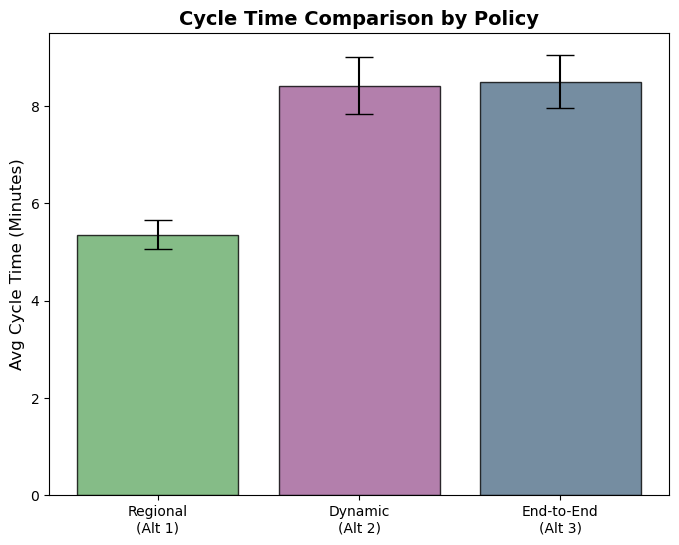

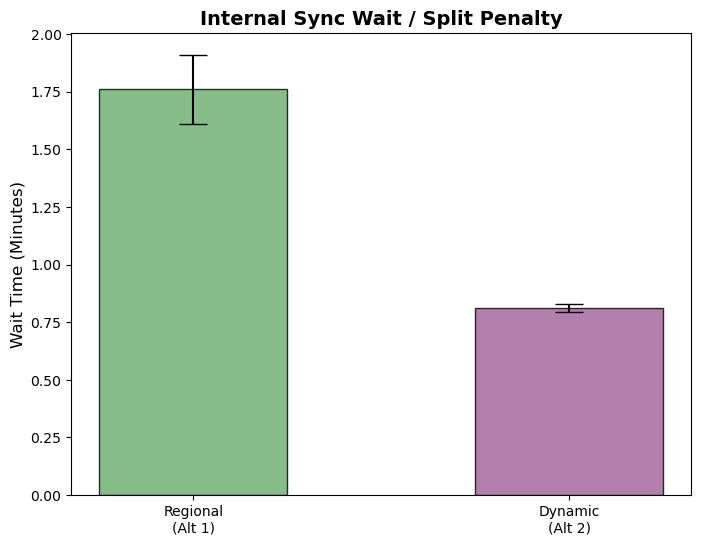

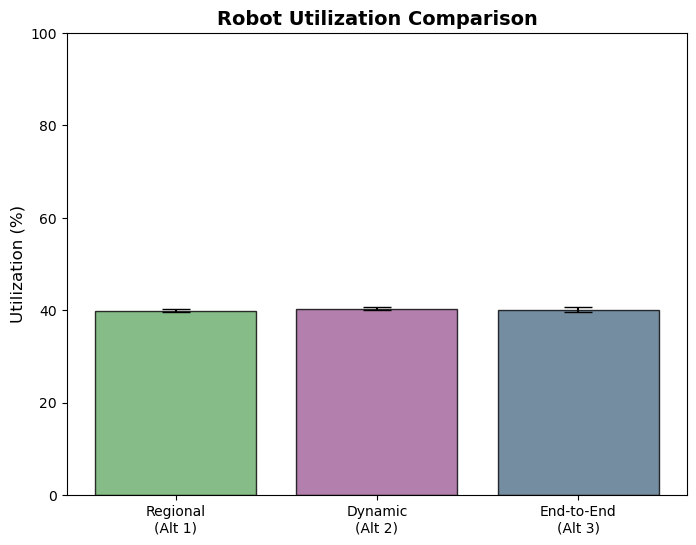

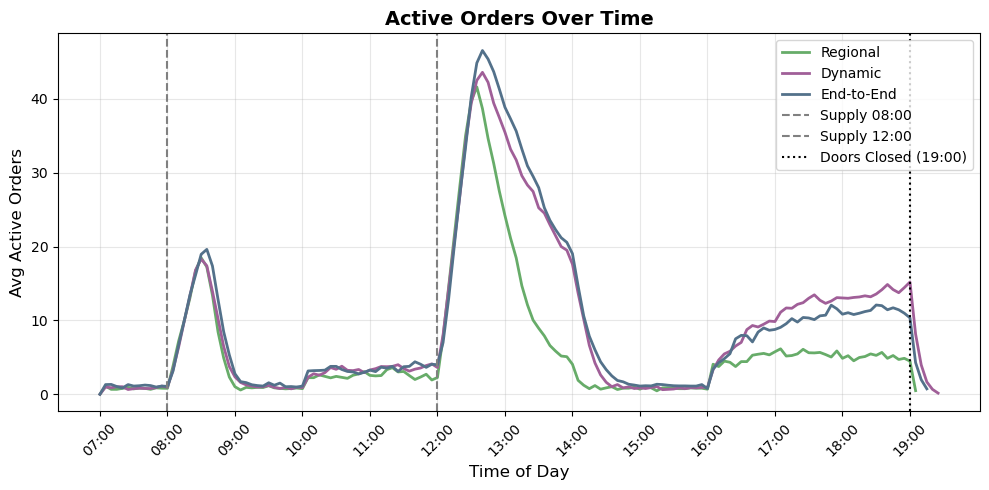

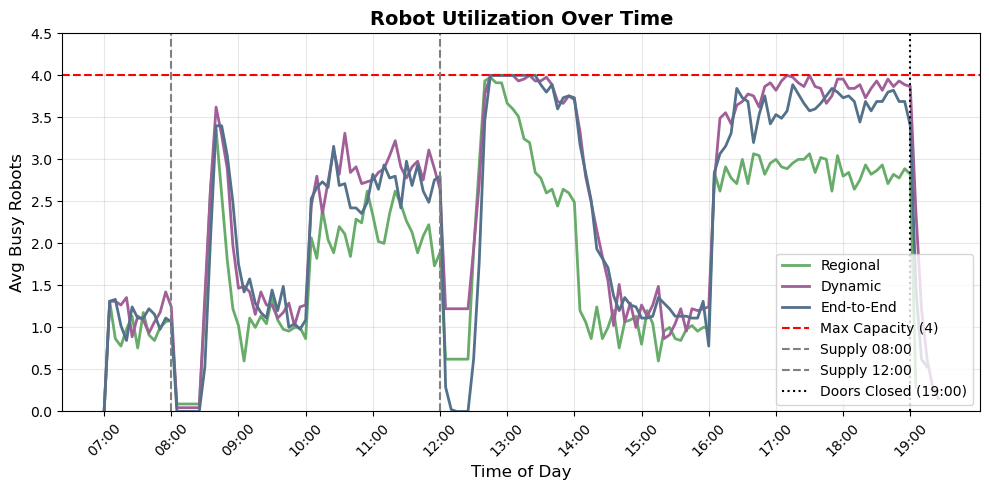

In [8]:
# ==========================================
# גרפים
# ==========================================


# 1. השוואת זמני שהייה
plt.figure(figsize=(8, 6))
modes = ['Regional\n(Alt 1)', 'Dynamic\n(Alt 2)', 'End-to-End\n(Alt 3)']
means = [np.mean(results['specialized']), np.mean(results['dynamic']), np.mean(results['end_to_end'])]
errors = [calc_ci(results['specialized'])[1], calc_ci(results['dynamic'])[1], calc_ci(results['end_to_end'])[1]]

plt.bar(modes, means, yerr=errors, capsize=10, color=["#67AC69", "#A05F98", "#53718A"], alpha=0.8, edgecolor='black')
plt.title("Cycle Time Comparison by Policy", fontsize=14, fontweight='bold')
plt.ylabel("Avg Cycle Time (Minutes)", fontsize=12)
plt.show()


# 2. השוואת זמן המתנה פנימי
# רלוונטי רק לחלופות 1 ו-2 המפצלות משימות
plt.figure(figsize=(8, 6))
sync_modes = ['Regional\n(Alt 1)', 'Dynamic\n(Alt 2)']
sync_means = [np.mean(sync_waits['specialized']), np.mean(sync_waits['dynamic'])]
sync_errors = [calc_ci(sync_waits['specialized'])[1], calc_ci(sync_waits['dynamic'])[1]]

plt.bar(sync_modes, sync_means, yerr=sync_errors, capsize=10, color=['#67AC69', '#A05F98'], alpha=0.8, edgecolor='black', width=0.5)
plt.title("Internal Sync Wait / Split Penalty", fontsize=14, fontweight='bold')
plt.ylabel("Wait Time (Minutes)", fontsize=12)
plt.show()


# 3. ניצולת רובוטים
plt.figure(figsize=(8, 6))
util_means = [np.mean(utils['specialized']), np.mean(utils['dynamic']), np.mean(utils['end_to_end'])]
util_errors = [calc_ci(utils['specialized'])[1], calc_ci(utils['dynamic'])[1], calc_ci(utils['end_to_end'])[1]]

plt.bar(modes, util_means, yerr=util_errors, capsize=10, color=['#67AC69', '#A05F98', '#53718A'], alpha=0.8, edgecolor='black')
plt.title("Robot Utilization Comparison", fontsize=14, fontweight='bold')
plt.ylabel("Utilization (%)", fontsize=12)
plt.ylim(0, 100)
plt.show()


# פונקציית עזר ליישור מערכים לטובת ציור גרפים ממוצעים (מוסיפה אפסים בסוף למערכים קצרים מדי)
def pad_with_zeros(arrays_list):
    if not arrays_list: return []
    max_len = max(len(arr) for arr in arrays_list)
    return [np.pad(arr, (0, max_len - len(arr)), 'constant') for arr in arrays_list]

# נמצא את המערך הארוך ביותר מבין כל ההרצות בכל החלופות כדי לבנות ציר זמן X ארוך מספיק
max_len_all = max(
    max((len(arr) for arr in history_queues['specialized']), default=0),
    max((len(arr) for arr in history_queues['dynamic']), default=0),
    max((len(arr) for arr in history_queues['end_to_end']), default=0)
)
extended_time_axis = np.arange(max_len_all) * 5.0 / 60.0 # קפיצות של 5 דקות (בשעות)

# חישוב ממוצע (עבור גרף 4) של הזמנות פעילות לכל חלופה
mean_active_specialized = np.mean(pad_with_zeros(history_queues['specialized']), axis=0) 
mean_active_dynamic = np.mean(pad_with_zeros(history_queues['dynamic']), axis=0) 
mean_active_end_to_end = np.mean(pad_with_zeros(history_queues['end_to_end']), axis=0) 

# חישוב ממוצע (עבור גרף 5) של רובוטים עסוקים לכל חלופה
mean_robots_specialized = np.mean(pad_with_zeros(history_robots['specialized']), axis=0) 
mean_robots_dynamic = np.mean(pad_with_zeros(history_robots['dynamic']), axis=0) 
mean_robots_end_to_end = np.mean(pad_with_zeros(history_robots['end_to_end']), axis=0) 

# טיפול בתוויות ציר X
tick_positions = np.arange(0, int(max(extended_time_axis))+1, 1)
tick_labels = [f"{int((7+h) % 24):02d}:00" for h in tick_positions]

# 4. עומס ממוצע לאורך שעות היום (השוואת 3 החלופות)
plt.figure(figsize=(10, 5))

# ציור 3 הקווים
plt.plot(extended_time_axis[:len(mean_active_specialized)], mean_active_specialized, color='#67AC69', linewidth=2, label='Regional')
plt.plot(extended_time_axis[:len(mean_active_dynamic)], mean_active_dynamic, color='#A05F98', linewidth=2, label='Dynamic')
plt.plot(extended_time_axis[:len(mean_active_end_to_end)], mean_active_end_to_end, color='#53718A', linewidth=2, label='End-to-End')


plt.axvline(x=1.0, color='gray', linestyle='--', label='Supply 08:00')
plt.axvline(x=5.0, color='gray', linestyle='--', label='Supply 12:00')
plt.axvline(x=12.0, color='black', linestyle=':', label='Doors Closed (19:00)')

plt.title("Active Orders Over Time", fontsize=14, fontweight='bold')
plt.xlabel("Time of Day", fontsize=12)
plt.ylabel("Avg Active Orders", fontsize=12)
plt.xticks(tick_positions, tick_labels, rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 5. ניצולת בזמן אמת (השוואת 3 החלופות)
plt.figure(figsize=(10, 5))

# ציור 3 הקווים
plt.plot(extended_time_axis[:len(mean_robots_specialized)], mean_robots_specialized, color='#67AC69', linewidth=2, label='Regional')
plt.plot(extended_time_axis[:len(mean_robots_dynamic)], mean_robots_dynamic, color='#A05F98', linewidth=2, label='Dynamic')
plt.plot(extended_time_axis[:len(mean_robots_end_to_end)], mean_robots_end_to_end, color='#53718A', linewidth=2, label='End-to-End')

plt.axhline(y=NUM_ROBOTS, color='red', linestyle='--', label='Max Capacity (4)')
plt.axvline(x=1.0, color='gray', linestyle='--', label='Supply 08:00')
plt.axvline(x=5.0, color='gray', linestyle='--', label='Supply 12:00')
plt.axvline(x=12.0, color='black', linestyle=':', label='Doors Closed (19:00)')

plt.title("Robot Utilization Over Time", fontsize=14, fontweight='bold')
plt.xlabel("Time of Day", fontsize=12)
plt.ylabel("Avg Busy Robots", fontsize=12)
plt.ylim(0, NUM_ROBOTS + 0.5) 
plt.xticks(tick_positions, tick_labels, rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Starting Sensitivity Analysis (This might take a while)


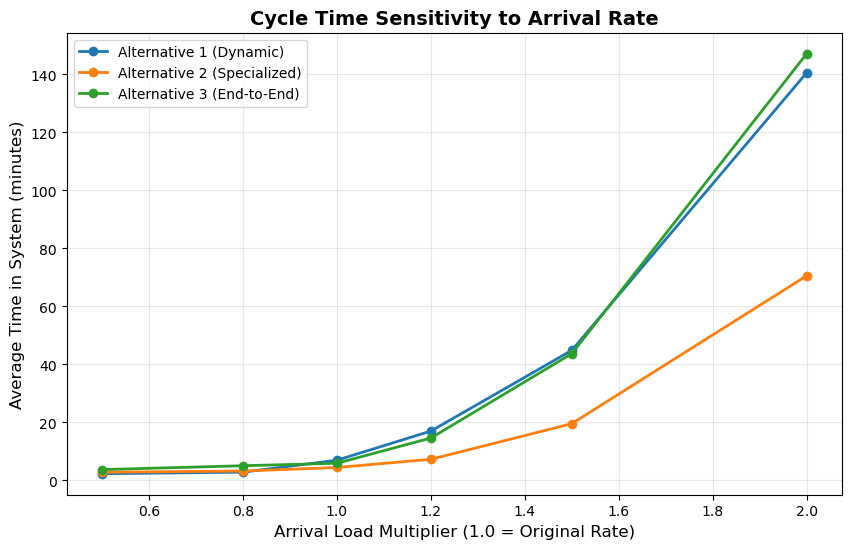

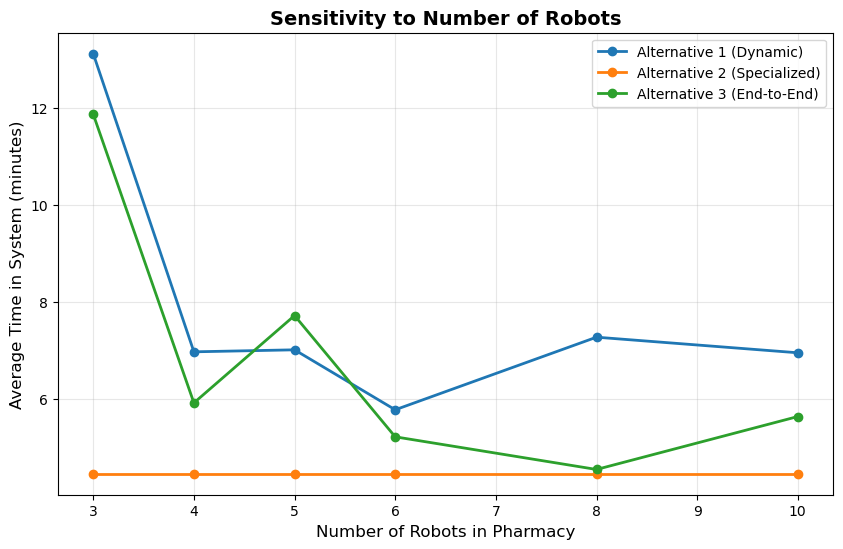

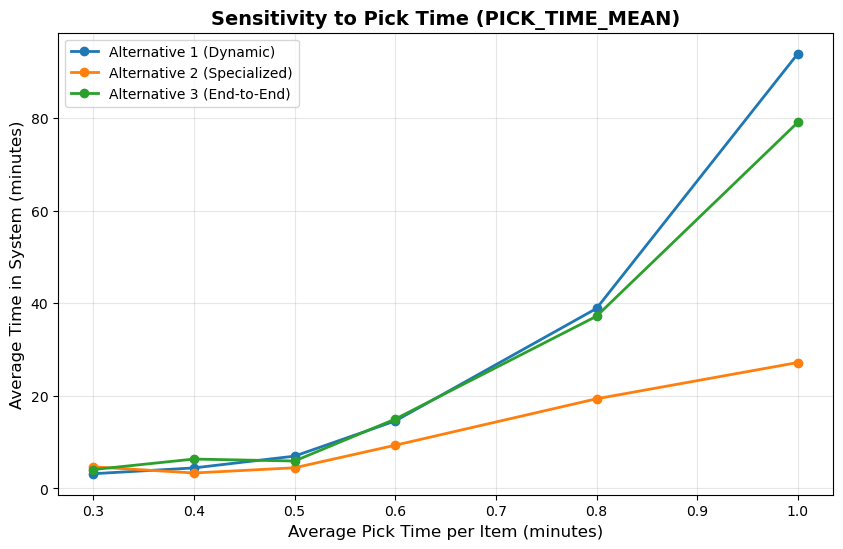

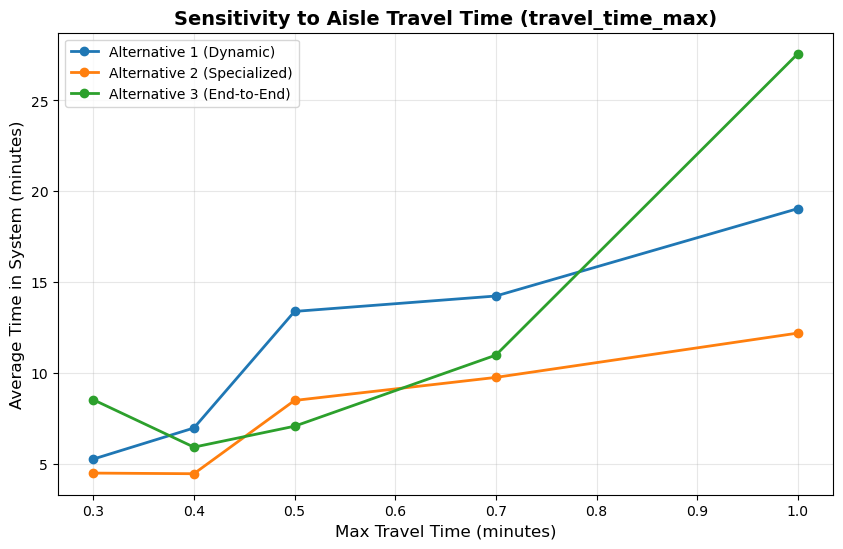

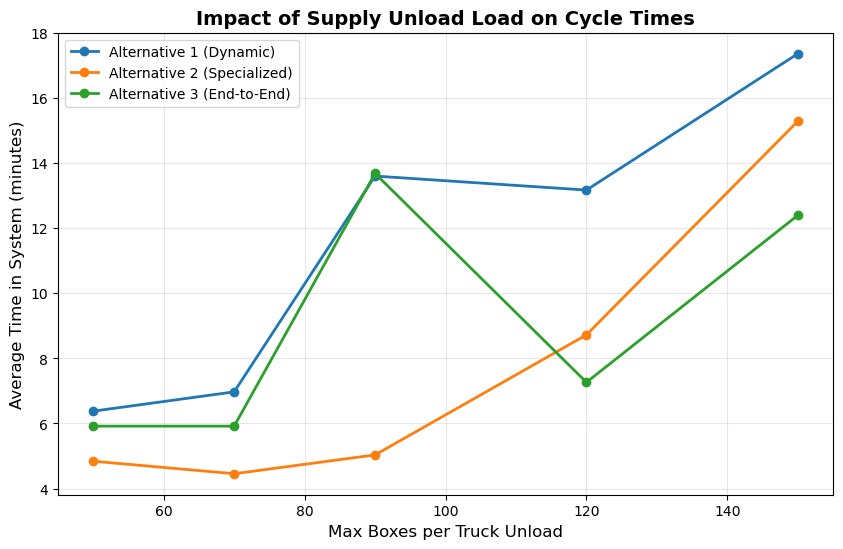

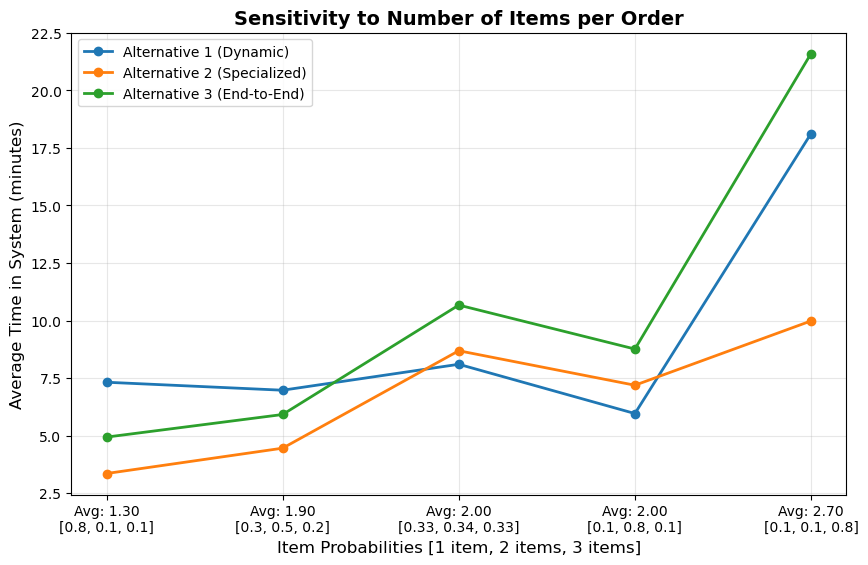

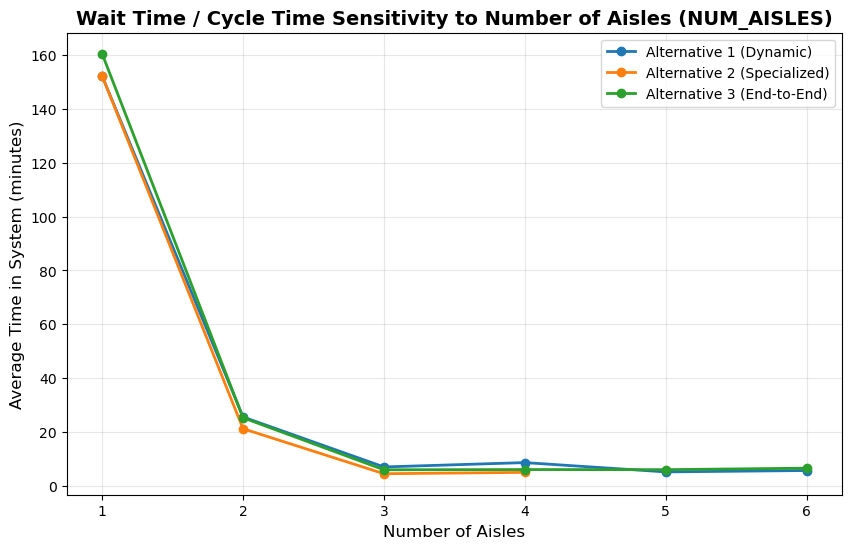

Sensitivity Analysis Completed Successfully! Intersections indicate where alternatives swap dominance


In [9]:
# ==========================================
# ניתוח רגישות והשוואת חלופות
# ==========================================
import copy
import matplotlib.pyplot as plt
import numpy as np
import simpy

def run_scenario(mode):
    # מריץ סימולציה לחלופה מסוימת ומחזיר את ממוצע זמן השהייה
    all_runs_avg_times = []
    
    for i in range(NUM_REPLICATIONS):
        # מגדירים seed ספציפי לכל חזרה (i), כדי שכל החלופות יחוו בדיוק את אותם ימים
        np.random.seed(42 + i)
        import random 
        random.seed(42 + i)
    
    env = simpy.Environment()
    try:
        # יצירת המערכת והרצתה עם החלופה הספציפית
        system = PharmacySystem(env, mode=mode)
        env.run()
        # אם היו לקוחות, נחזיר את זמן השהייה הממוצע
        if len(system.stat_cycle_times) > 0:
            return np.mean(system.stat_cycle_times)
        else:
            return np.nan
    except Exception as e:
        # למקרה שחלופה מסוימת קורסת (למשל פחות מ-3 רובוטים בחלופה 2 שדורשת מינימום 3)
        pass
# מחזיר את הממוצע של כל ההרצות (Average of Averages)
    if len(all_runs_avg_times) > 0:
        return np.mean(all_runs_avg_times)
    else:
        return np.nan

# נגדיר את שמות החלופות להצגה בגרפים
modes = ['dynamic', 'specialized', 'end_to_end']
mode_names = {
    'dynamic': 'Alternative 1 (Dynamic)', 
    'specialized': 'Alternative 2 (Specialized)', 
    'end_to_end': 'Alternative 3 (End-to-End)'
}

def plot_sensitivity(param_name, param_values, xlabel, title):
    # פונקציה גנרית המציירת גרף רגישות עבור פרמטר נתון
    results = {mode: [] for mode in modes}
    
    # שומרים את ערך הפרמטר המקורי כדי לא להרוס את שאר הקוד במחברת
    original_value = globals().get(param_name)
    
    for val in param_values:
        # דורסים זמנית את הפרמטר הגלובלי
        globals()[param_name] = val
        
        for mode in modes:
            avg_time = run_scenario(mode)
            results[mode].append(avg_time)
            
    # מחזירים את הפרמטר למצבו המקורי
    if original_value is not None:
        globals()[param_name] = original_value
        
    # ציור הגרף
    plt.figure(figsize=(10, 6))
    for mode in modes:
        # ציור הקו. ערכים חסרים (במידה וחלופה קרסה) פשוט לא יצוירו, מה שמונע שגיאות
        plt.plot(param_values, results[mode], marker='o', label=mode_names[mode], linewidth=2)
        
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel("Average Time in System (minutes)", fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_arrival_rate_sensitivity(scale_factors):
    # פונקציה ספציפית לניתוח רגישות של קצב הגעות המוגדר כמילון
    results = {mode: [] for mode in modes}
    
    # שמירת המילון המקורי וקצב המקסימום המקורי
    original_hourly_rates = copy.deepcopy(globals().get('HOURLY_RATES'))
    original_max_lambda = globals().get('MAX_LAMBDA_PER_MIN')
    
    for scale in scale_factors:
        # עדכון המילון עם מכפיל עומס
        globals()['HOURLY_RATES'] = {k: v * scale for k, v in original_hourly_rates.items()}
        globals()['MAX_LAMBDA_PER_MIN'] = max(globals()['HOURLY_RATES'].values()) / 60.0
        
        for mode in modes:
            results[mode].append(run_scenario(mode))
            
    # שחזור המשתנים
    globals()['HOURLY_RATES'] = original_hourly_rates
    globals()['MAX_LAMBDA_PER_MIN'] = original_max_lambda
    
    # ציור הגרף
    plt.figure(figsize=(10, 6))
    for mode in modes:
        plt.plot(scale_factors, results[mode], marker='o', label=mode_names[mode], linewidth=2)
        
    plt.title("Cycle Time Sensitivity to Arrival Rate", fontsize=14, fontweight='bold')
    plt.xlabel("Arrival Load Multiplier (1.0 = Original Rate)", fontsize=12)
    plt.ylabel("Average Time in System (minutes)", fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_order_size_sensitivity(distributions_list):
    # מנתח את הרגישות של המערכת להתפלגות כמות התרופות
    # distributions_list היא רשימה של מילונים, כל אחד מייצג תרחיש
    results = {mode: [] for mode in modes}
    
    # שמירת המילון המקורי כדי לשחזר אותו בסוף
    original_probs = copy.deepcopy(globals().get('ORDER_SIZE_PROBS'))
    
    x_labels = [] 
    
    for probs_dict in distributions_list:
        # דורסים זמנית את המשתנה הגלובלי עם המילון של התרחיש הנוכחי
        globals()['ORDER_SIZE_PROBS'] = probs_dict
        
        # חישוב תוחלת (ממוצע פריטים להזמנה) להצגה בגרף
        expected_items = sum(k * v for k, v in probs_dict.items())
        
        # יצירת טקסט לציר ה-X שמציג את התוחלת ואת ההסתברויות
        probs_values = [probs_dict[1], probs_dict[2], probs_dict[3]]
        x_labels.append(f"Avg: {expected_items:.2f}\n{probs_values}")
        
        # הרצת החלופות עבור התרחיש הנוכחי
        for mode in modes:
            results[mode].append(run_scenario(mode))
            
    # שחזור המשתנה המקורי! קריטי כדי לא להרוס את שאר המחברת
    if original_probs is not None:
        globals()['ORDER_SIZE_PROBS'] = original_probs
    
    # ציור הגרף
    plt.figure(figsize=(10, 6))
    x_positions = range(len(distributions_list))
    
    for mode in modes:
        plt.plot(x_positions, results[mode], marker='o', label=mode_names[mode], linewidth=2)
        
    plt.title("Sensitivity to Number of Items per Order", fontsize=14, fontweight='bold')
    plt.xticks(x_positions, x_labels)
    plt.xlabel("Item Probabilities [1 item, 2 items, 3 items]", fontsize=12)
    plt.ylabel("Average Time in System (minutes)", fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


print("Starting Sensitivity Analysis (This might take a while)")

# 1. ניתוח רגישות קצב הגעות - מראה עבור איזה עומס הגעות חלופה אחרת עדיפה
plot_arrival_rate_sensitivity([0.5, 0.8, 1.0, 1.2, 1.5, 2.0])

# 2. ניתוח רגישות למספר הרובוטים
plot_sensitivity('NUM_ROBOTS', [3, 4, 5, 6, 8, 10], "Number of Robots in Pharmacy", "Sensitivity to Number of Robots")

# 3. ניתוח רגישות לזמן ליקוט ממוצע (עוזר להבין באיזו חלופה כדאי לבחור אם הרובוטים איטיים/מהירים יותר)
plot_sensitivity('PICK_TIME_MEAN', [0.3, 0.4, 0.5, 0.6, 0.8, 1.0], "Average Pick Time per Item (minutes)", "Sensitivity to Pick Time (PICK_TIME_MEAN)")

# 4. ניתוח רגישות לזמן הנסיעה המקסימלי (מרחק/מהירות הפיזית למסדרונות)
plot_sensitivity('travel_time_max', [0.3, 0.4, 0.5, 0.7, 1.0], "Max Travel Time (minutes)", "Sensitivity to Aisle Travel Time (travel_time_max)")

# 5. ניתוח רגישות לעומס קבלת סחורה במשאית
plot_sensitivity('SUPPLY_MAX_BOXES', [50, 70, 90, 120, 150], "Max Boxes per Truck Unload", "Impact of Supply Unload Load on Cycle Times")

# 6. ניתוח רגישות להתפלגות כמות תרופות

distributions_to_test = [
    {1: 0.8, 2: 0.1, 3: 0.1},    # תרחיש קל: כמעט כולם קונים רק פריט אחד
    {1: 0.3, 2: 0.5, 3: 0.2},    # התרחיש המקורי שלך (הוספתי אותו כדי שתראי איפה הוא עומד ביחס לאחרים)
    {1: 0.33, 2: 0.34, 3: 0.33}, # תרחיש מאוזן: שליש לכל אפשרות
    {1: 0.1, 2: 0.8, 3: 0.1},    # תרחיש עמוס בינוני: הרוב קונים 2 פריטים
    {1: 0.1, 2: 0.1, 3: 0.8}     # תרחיש כבד: כמעט כולם קונים 3 פריטים
]

plot_order_size_sensitivity(distributions_to_test)

# 7. ניתוח רגישות לכמות מסדרונות
plot_sensitivity(
    'NUM_AISLES', 
    [1, 2, 3, 4, 5, 6], 
    "Number of Aisles", 
    "Wait Time / Cycle Time Sensitivity to Number of Aisles (NUM_AISLES)"
)

print("Sensitivity Analysis Completed Successfully! Intersections indicate where alternatives swap dominance")

Starting Utilization Sensitivity Analysis (This might take a while)


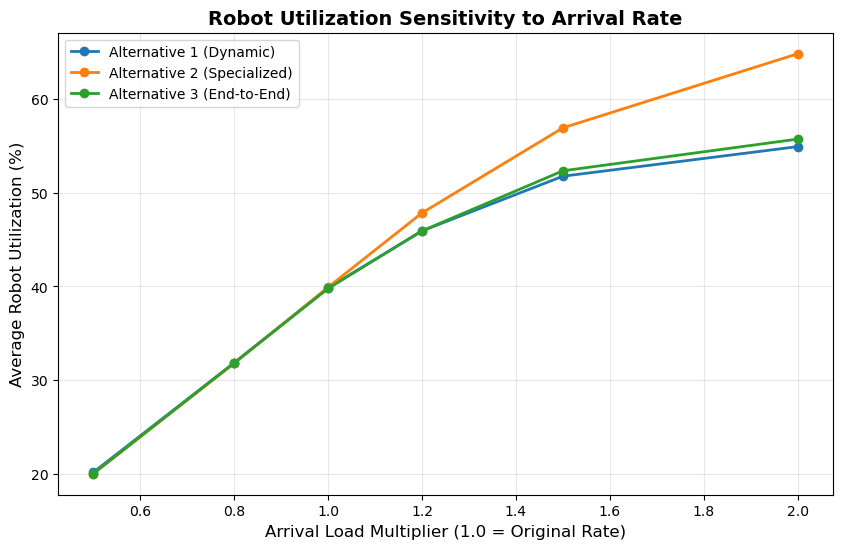

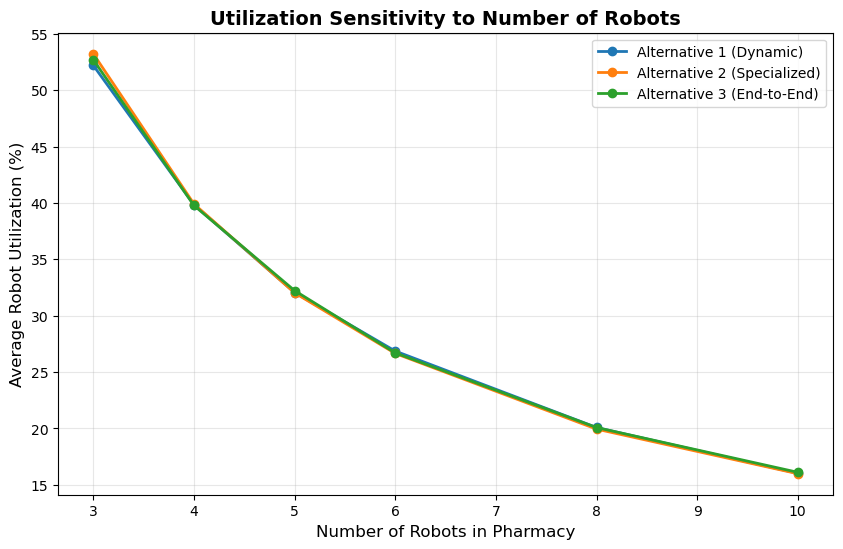

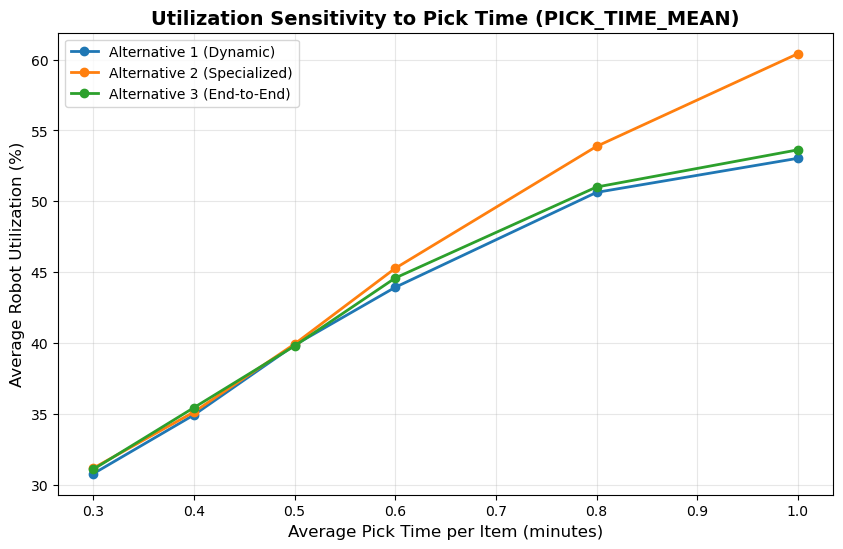

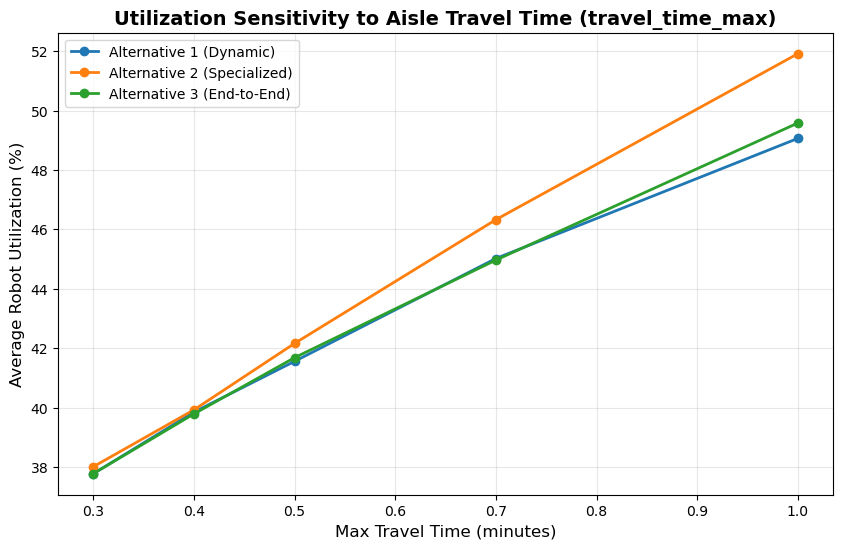

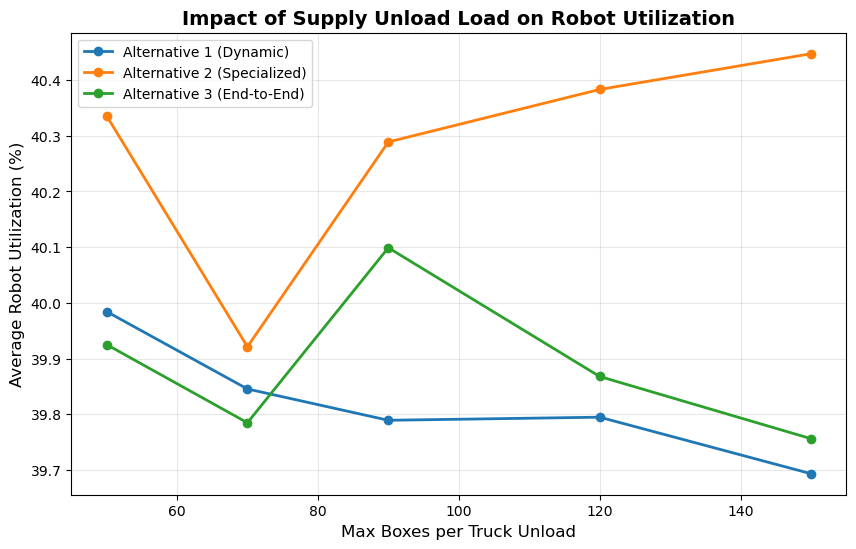

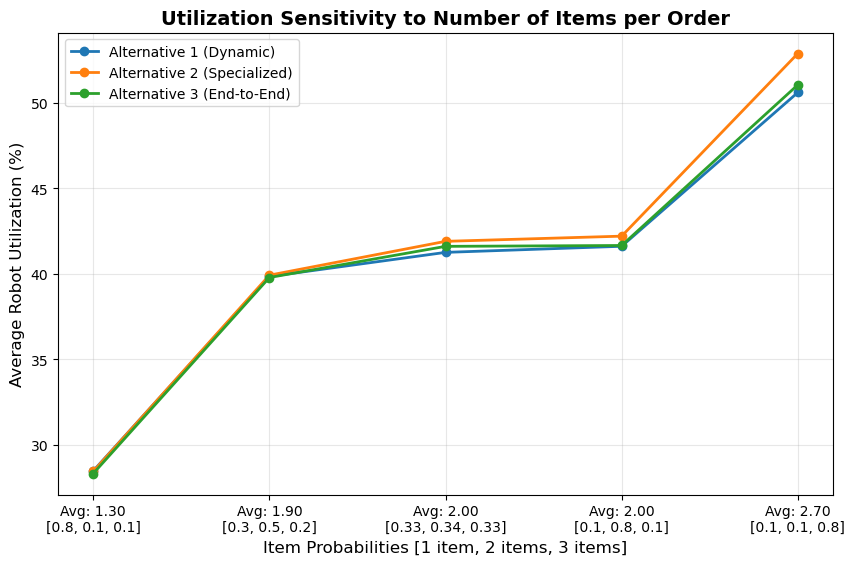

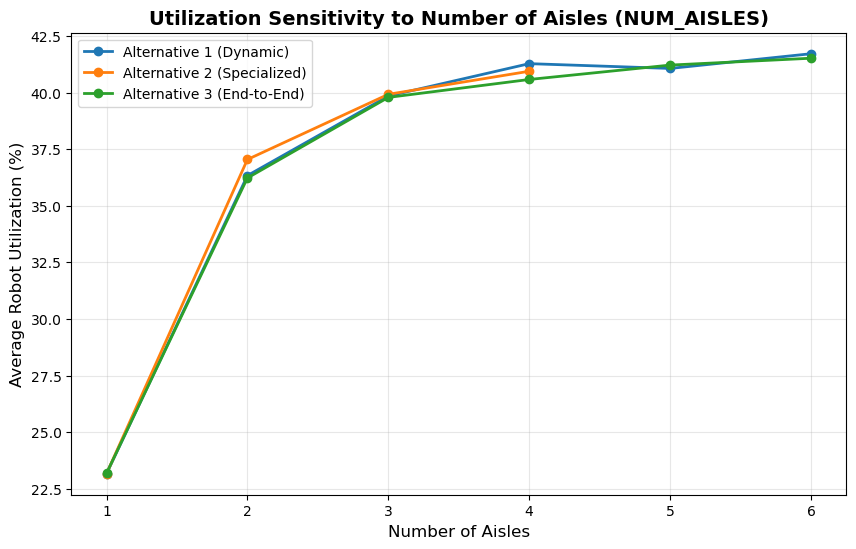

Utilization Sensitivity Analysis Completed Successfully!


In [10]:
# =========================================================
# ניתוח רגישות - ממוקד נצילות רובוטים
# =========================================================

def run_scenario_utilization(mode):
    # מריץ סימולציה לחלופה מסוימת ומחזיר את ממוצע הנצילות
    all_runs_utilizations = []
    
    for i in range(NUM_REPLICATIONS):
        np.random.seed(42 + i)
        import random 
        random.seed(42 + i)
    
        env = simpy.Environment()
        try:
            system = PharmacySystem(env, mode=mode)
            env.run()
            
            current_util = (system.total_busy_time / (system.env.now * NUM_ROBOTS)) * 100
            
            all_runs_utilizations.append(current_util)
        except Exception as e:
            pass
            
    # מחזיר את הממוצע של כל ההרצות (Average of Averages)
    if len(all_runs_utilizations) > 0:
        return np.mean(all_runs_utilizations)
    else:
        return np.nan

# נגדיר את שמות החלופות להצגה בגרפים
modes = ['dynamic', 'specialized', 'end_to_end']
mode_names = {
    'dynamic': 'Alternative 1 (Dynamic)', 
    'specialized': 'Alternative 2 (Specialized)', 
    'end_to_end': 'Alternative 3 (End-to-End)'
}

def plot_sensitivity_utilization(param_name, param_values, xlabel, title):
    # פונקציה גנרית המציירת גרף רגישות לנצילות עבור פרמטר נתון
    results = {mode: [] for mode in modes}
    original_value = globals().get(param_name)
    
    for val in param_values:
        globals()[param_name] = val
        for mode in modes:
            util = run_scenario_utilization(mode)
            results[mode].append(util)
            
    if original_value is not None:
        globals()[param_name] = original_value
        
    plt.figure(figsize=(10, 6))
    for mode in modes:
        plt.plot(param_values, results[mode], marker='o', label=mode_names[mode], linewidth=2)
        
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel("Average Robot Utilization (%)", fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_arrival_rate_sensitivity_utilization(scale_factors):
    # ניתוח רגישות של קצב הגעות - לנצילות
    results = {mode: [] for mode in modes}
    
    original_hourly_rates = copy.deepcopy(globals().get('HOURLY_RATES'))
    original_max_lambda = globals().get('MAX_LAMBDA_PER_MIN')
    
    for scale in scale_factors:
        globals()['HOURLY_RATES'] = {k: v * scale for k, v in original_hourly_rates.items()}
        globals()['MAX_LAMBDA_PER_MIN'] = max(globals()['HOURLY_RATES'].values()) / 60.0
        
        for mode in modes:
            results[mode].append(run_scenario_utilization(mode))
            
    globals()['HOURLY_RATES'] = original_hourly_rates
    globals()['MAX_LAMBDA_PER_MIN'] = original_max_lambda
    
    plt.figure(figsize=(10, 6))
    for mode in modes:
        plt.plot(scale_factors, results[mode], marker='o', label=mode_names[mode], linewidth=2)
        
    plt.title("Robot Utilization Sensitivity to Arrival Rate", fontsize=14, fontweight='bold')
    plt.xlabel("Arrival Load Multiplier (1.0 = Original Rate)", fontsize=12)
    plt.ylabel("Average Robot Utilization (%)", fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_order_size_sensitivity_utilization(distributions_list):
    # מנתח את רגישות הנצילות להתפלגות כמות התרופות
    results = {mode: [] for mode in modes}
    original_probs = copy.deepcopy(globals().get('ORDER_SIZE_PROBS'))
    x_labels = [] 
    
    for probs_dict in distributions_list:
        globals()['ORDER_SIZE_PROBS'] = probs_dict
        expected_items = sum(k * v for k, v in probs_dict.items())
        probs_values = [probs_dict[1], probs_dict[2], probs_dict[3]]
        x_labels.append(f"Avg: {expected_items:.2f}\n{probs_values}")
        
        for mode in modes:
            results[mode].append(run_scenario_utilization(mode))
            
    if original_probs is not None:
        globals()['ORDER_SIZE_PROBS'] = original_probs
    
    plt.figure(figsize=(10, 6))
    x_positions = range(len(distributions_list))
    
    for mode in modes:
        plt.plot(x_positions, results[mode], marker='o', label=mode_names[mode], linewidth=2)
        
    plt.title("Utilization Sensitivity to Number of Items per Order", fontsize=14, fontweight='bold')
    plt.xticks(x_positions, x_labels)
    plt.xlabel("Item Probabilities [1 item, 2 items, 3 items]", fontsize=12)
    plt.ylabel("Average Robot Utilization (%)", fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

print("Starting Utilization Sensitivity Analysis (This might take a while)")

# 1. ניתוח רגישות קצב הגעות - מראה איך העומס משפיע על הנצילות בכל חלופה
plot_arrival_rate_sensitivity_utilization([0.5, 0.8, 1.0, 1.2, 1.5, 2.0])

# 2. ניתוח רגישות למספר הרובוטים
plot_sensitivity_utilization('NUM_ROBOTS', [3, 4, 5, 6, 8, 10], "Number of Robots in Pharmacy", "Utilization Sensitivity to Number of Robots")

# 3. ניתוח רגישות לזמן ליקוט ממוצע 
plot_sensitivity_utilization('PICK_TIME_MEAN', [0.3, 0.4, 0.5, 0.6, 0.8, 1.0], "Average Pick Time per Item (minutes)", "Utilization Sensitivity to Pick Time (PICK_TIME_MEAN)")

# 4. ניתוח רגישות לזמן הנסיעה המקסימלי
plot_sensitivity_utilization('travel_time_max', [0.3, 0.4, 0.5, 0.7, 1.0], "Max Travel Time (minutes)", "Utilization Sensitivity to Aisle Travel Time (travel_time_max)")

# 5. ניתוח רגישות לעומס קבלת סחורה במשאית
plot_sensitivity_utilization('SUPPLY_MAX_BOXES', [50, 70, 90, 120, 150], "Max Boxes per Truck Unload", "Impact of Supply Unload Load on Robot Utilization")

# 6. ניתוח רגישות להתפלגות כמות תרופות
distributions_to_test = [
    {1: 0.8, 2: 0.1, 3: 0.1},    
    {1: 0.3, 2: 0.5, 3: 0.2},    
    {1: 0.33, 2: 0.34, 3: 0.33}, 
    {1: 0.1, 2: 0.8, 3: 0.1},    
    {1: 0.1, 2: 0.1, 3: 0.8}     
]

plot_order_size_sensitivity_utilization(distributions_to_test)

# 7. ניתוח רגישות כמות מסדרונות
plot_sensitivity_utilization(
    'NUM_AISLES', 
    [1, 2, 3, 4, 5, 6], 
    "Number of Aisles", 
    "Utilization Sensitivity to Number of Aisles (NUM_AISLES)"
)

print("Utilization Sensitivity Analysis Completed Successfully!")


 3. SENSITIVITY ANALYSIS
Running Scenario 1: High Load (+20% Arrivals)
Running Scenario 2: Slower Robots (+15% Picking Time)
Running Scenario 3: Heavier Customer Orders (More items)
Running Scenario 4: Robot Failure (3 instead of 4)
Running Scenario 5: Heavy Supply Truck (+ 20~50 boxes)
Running Scenario 6: Slower Unloading Time
Running Scenario 7: Changed Supply Times (10:00 and 14:00)
Running Scenario 8: Changed Supply Times (07:00 and 18:00)
Running Scenario 9: More Robots (8 instead of 4)
Running Scenario 10: Low Load (-20% Arrivals)

 SENSITIVITY ANALYSIS RESULTS (Cycle Time)

Statistical Winner identified from Baseline: specialized

Scenario 1: High Load (+20% Arrivals)
   - specialized  Cycle Time:  8.70 ± 0.53 mins  [ 8.17 ,  9.23]
   - dynamic      Cycle Time: 17.18 ± 0.97 mins  [16.21 , 18.14]
   - end_to_end   Cycle Time: 17.15 ± 1.05 mins  [16.10 , 18.20]
   --- Statistical Comparison (Paired T-test) ---
   specialized vs dynamic: Diff CI [-9.55 , -7.40] -> specialized is F

,חלופה,זמן שהייה (דקות),זמן סנכרון פנימי (דקות),ניצולת (%)
0,Alt 1 (Regional),8.70 ± 0.53,3.36 ± 0.28,48.71% ± 0.52%
1,Alt 2 (Dynamic),17.18 ± 0.97,0.88 ± 0.02,48.69% ± 0.44%
2,Alt 3 (End-to-End),17.15 ± 1.05,-,48.38% ± 0.46%


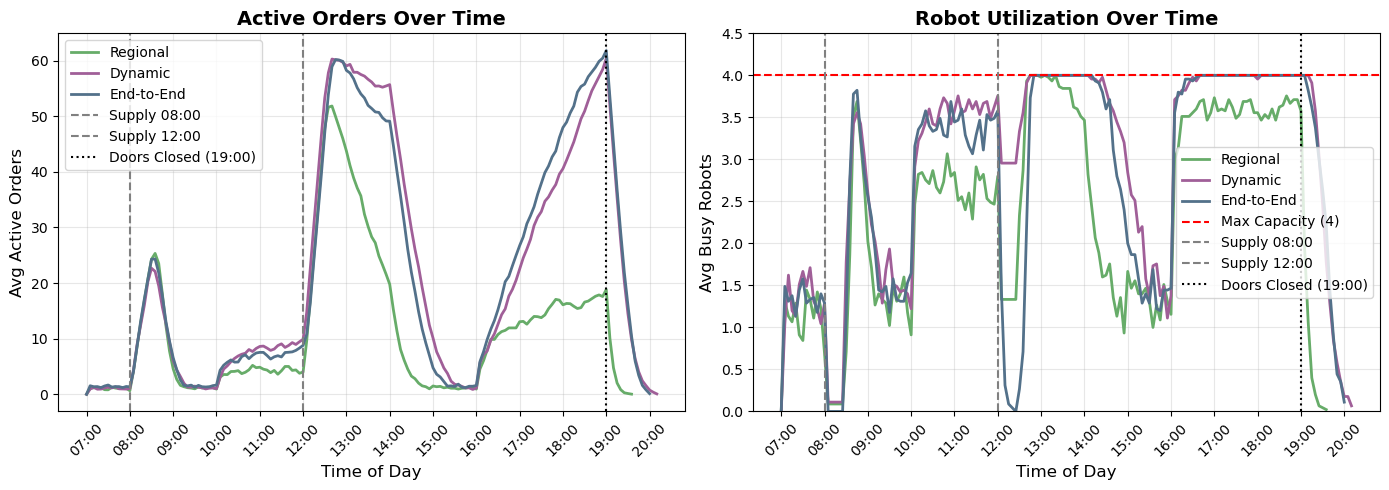

----------------------------------------------------------------------

Scenario 2: Slower Robots (+15% Picking Time)
   - specialized  Cycle Time:  6.80 ± 0.45 mins  [ 6.35 ,  7.24]
   - dynamic      Cycle Time: 12.68 ± 0.89 mins  [11.79 , 13.57]
   - end_to_end   Cycle Time: 12.06 ± 0.78 mins  [11.28 , 12.83]
   --- Statistical Comparison (Paired T-test) ---
   specialized vs dynamic: Diff CI [-6.86 , -4.91] -> specialized is FASTER
   specialized vs end_to_end: Diff CI [-6.17 , -4.35] -> specialized is FASTER
   dynamic vs end_to_end: Diff CI [-0.60 ,  1.84] -> No significant diff
   -> Robustness check: PASSED

 מדדים מסכמים לתרחיש:


,חלופה,זמן שהייה (דקות),זמן סנכרון פנימי (דקות),ניצולת (%)
0,Alt 1 (Regional),6.80 ± 0.45,2.50 ± 0.21,43.91% ± 0.38%
1,Alt 2 (Dynamic),12.68 ± 0.89,0.93 ± 0.02,44.51% ± 0.45%
2,Alt 3 (End-to-End),12.06 ± 0.78,-,44.77% ± 0.48%


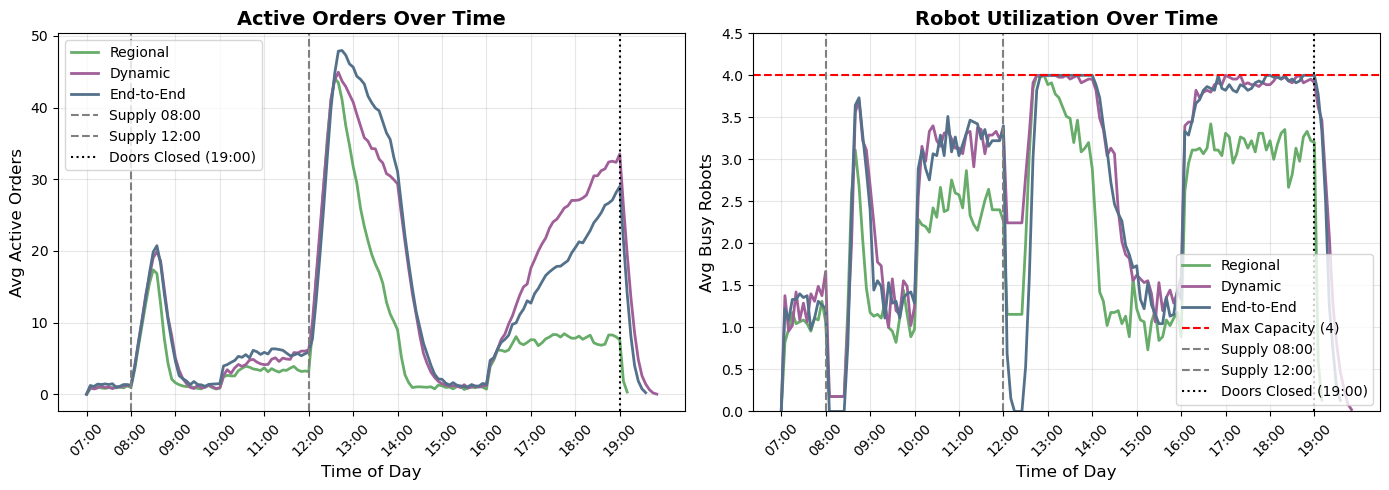

----------------------------------------------------------------------

Scenario 3: Heavier Orders (More items)
   - specialized  Cycle Time:  8.25 ± 0.48 mins  [ 7.77 ,  8.73]
   - dynamic      Cycle Time: 16.14 ± 1.11 mins  [15.03 , 17.25]
   - end_to_end   Cycle Time: 15.13 ± 1.15 mins  [13.98 , 16.29]
   --- Statistical Comparison (Paired T-test) ---
   specialized vs dynamic: Diff CI [-8.99 , -6.78] -> specialized is FASTER
   specialized vs end_to_end: Diff CI [-8.13 , -5.63] -> specialized is FASTER
   dynamic vs end_to_end: Diff CI [-0.37 ,  2.38] -> No significant diff
   -> Robustness check: PASSED

 מדדים מסכמים לתרחיש:


,חלופה,זמן שהייה (דקות),זמן סנכרון פנימי (דקות),ניצולת (%)
0,Alt 1 (Regional),8.25 ± 0.48,3.10 ± 0.24,47.38% ± 0.53%
1,Alt 2 (Dynamic),16.14 ± 1.11,0.97 ± 0.02,47.82% ± 0.59%
2,Alt 3 (End-to-End),15.13 ± 1.15,-,47.75% ± 0.54%


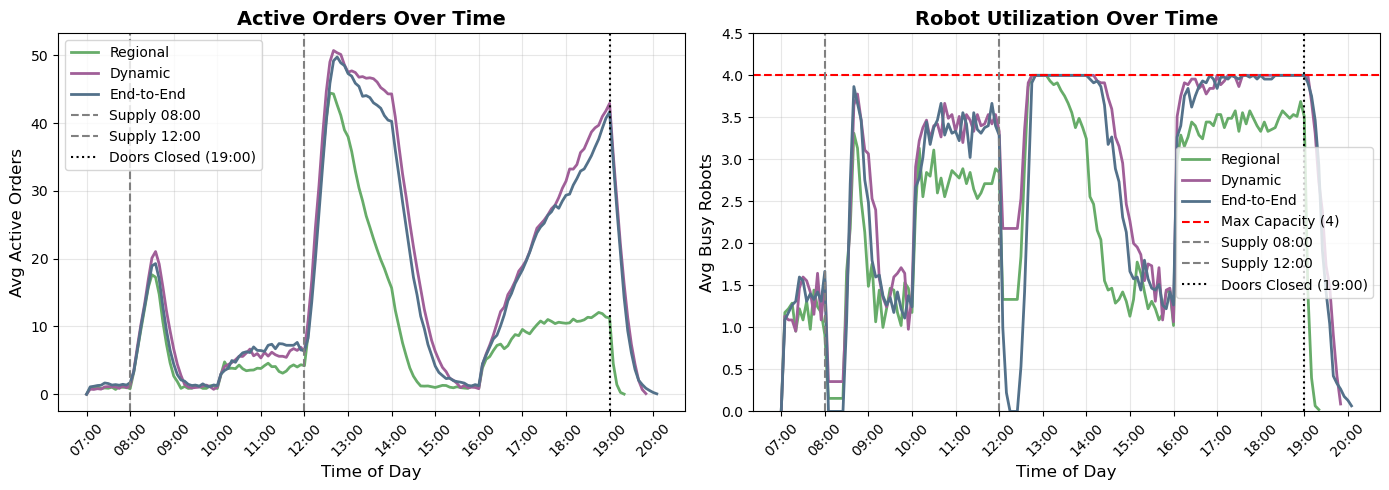

----------------------------------------------------------------------

Scenario 4: 3 Robots (Failure)
   - specialized  Cycle Time:  5.86 ± 0.34 mins  [ 5.52 ,  6.20]
   - dynamic      Cycle Time: 12.37 ± 0.89 mins  [11.48 , 13.26]
   - end_to_end   Cycle Time: 11.45 ± 0.82 mins  [10.62 , 12.27]
   --- Statistical Comparison (Paired T-test) ---
   specialized vs dynamic: Diff CI [-7.40 , -5.61] -> specialized is FASTER
   specialized vs end_to_end: Diff CI [-6.40 , -4.77] -> specialized is FASTER
   dynamic vs end_to_end: Diff CI [-0.24 ,  2.08] -> No significant diff
   -> Robustness check: PASSED

 מדדים מסכמים לתרחיש:


,חלופה,זמן שהייה (דקות),זמן סנכרון פנימי (דקות),ניצולת (%)
0,Alt 1 (Regional),5.86 ± 0.34,1.87 ± 0.14,54.05% ± 0.54%
1,Alt 2 (Dynamic),12.37 ± 0.89,0.61 ± 0.01,53.65% ± 0.45%
2,Alt 3 (End-to-End),11.45 ± 0.82,-,53.68% ± 0.67%


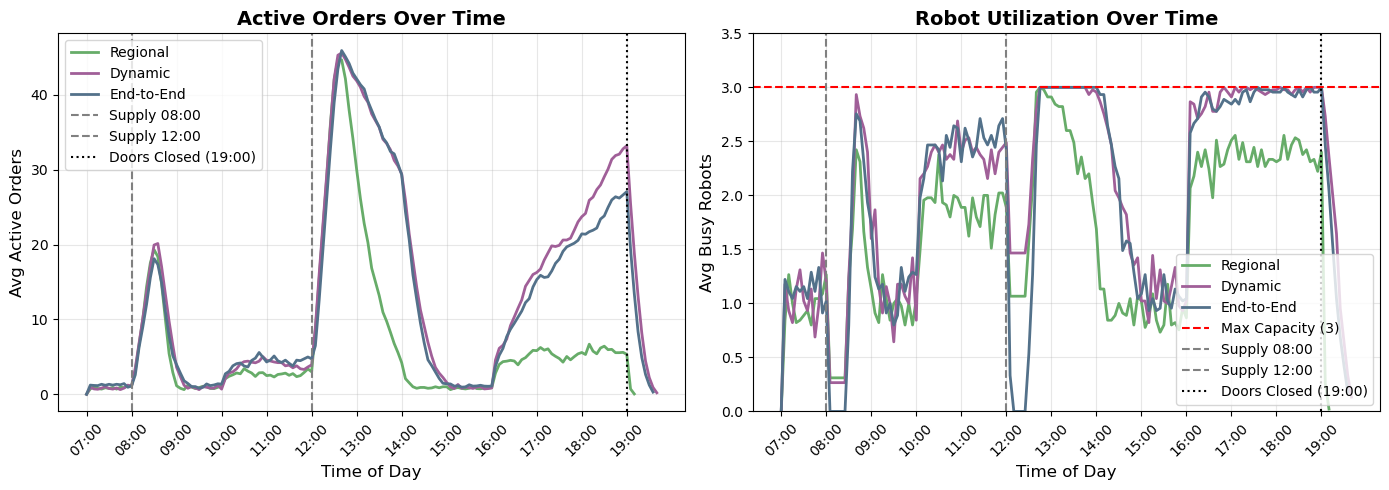

----------------------------------------------------------------------

Scenario 5: Heavy Truck (More boxes)
   - specialized  Cycle Time:  8.57 ± 0.57 mins  [ 8.00 ,  9.15]
   - dynamic      Cycle Time: 11.26 ± 0.80 mins  [10.46 , 12.06]
   - end_to_end   Cycle Time: 11.06 ± 0.75 mins  [10.31 , 11.82]
   --- Statistical Comparison (Paired T-test) ---
   specialized vs dynamic: Diff CI [-3.57 , -1.81] -> specialized is FASTER
   specialized vs end_to_end: Diff CI [-3.45 , -1.53] -> specialized is FASTER
   dynamic vs end_to_end: Diff CI [-0.71 ,  1.12] -> No significant diff
   -> Robustness check: PASSED

 מדדים מסכמים לתרחיש:


,חלופה,זמן שהייה (דקות),זמן סנכרון פנימי (דקות),ניצולת (%)
0,Alt 1 (Regional),8.57 ± 0.57,2.20 ± 0.18,40.45% ± 0.46%
1,Alt 2 (Dynamic),11.26 ± 0.80,0.82 ± 0.02,40.52% ± 0.49%
2,Alt 3 (End-to-End),11.06 ± 0.75,-,40.35% ± 0.44%


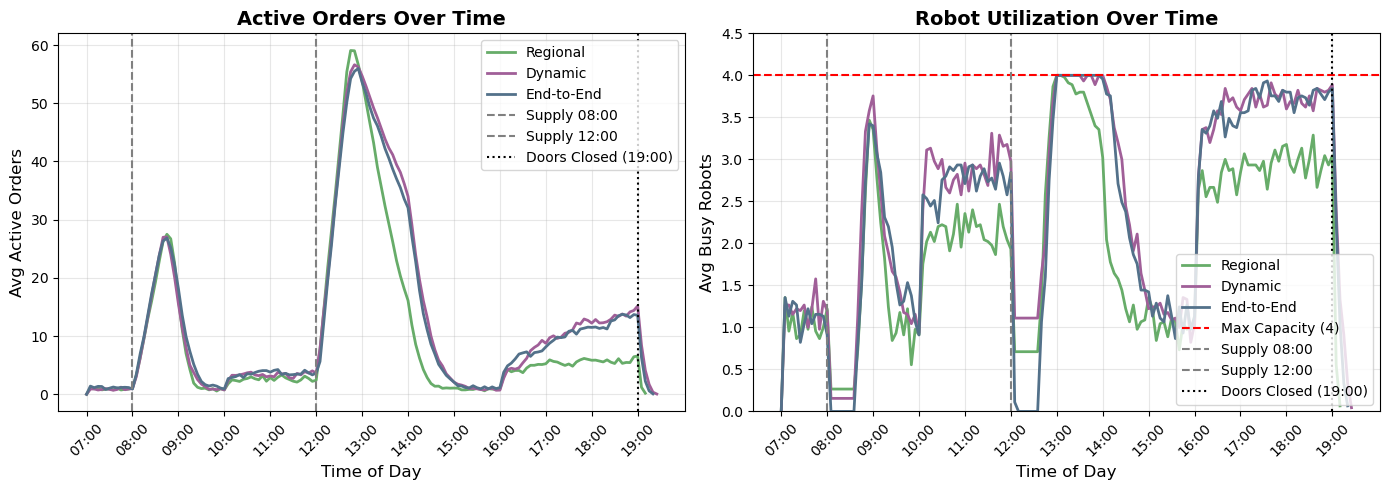

----------------------------------------------------------------------

Scenario 6: Slow Unloading
   - specialized  Cycle Time:  6.80 ± 0.34 mins  [ 6.46 ,  7.13]
   - dynamic      Cycle Time:  9.13 ± 0.56 mins  [ 8.57 ,  9.69]
   - end_to_end   Cycle Time:  9.70 ± 0.62 mins  [ 9.08 , 10.31]
   --- Statistical Comparison (Paired T-test) ---
   specialized vs dynamic: Diff CI [-2.98 , -1.68] -> specialized is FASTER
   specialized vs end_to_end: Diff CI [-3.56 , -2.24] -> specialized is FASTER
   dynamic vs end_to_end: Diff CI [-1.39 ,  0.25] -> No significant diff
   -> Robustness check: PASSED

 מדדים מסכמים לתרחיש:


,חלופה,זמן שהייה (דקות),זמן סנכרון פנימי (דקות),ניצולת (%)
0,Alt 1 (Regional),6.80 ± 0.34,2.00 ± 0.13,40.50% ± 0.37%
1,Alt 2 (Dynamic),9.13 ± 0.56,0.82 ± 0.02,39.91% ± 0.49%
2,Alt 3 (End-to-End),9.70 ± 0.62,-,40.38% ± 0.43%


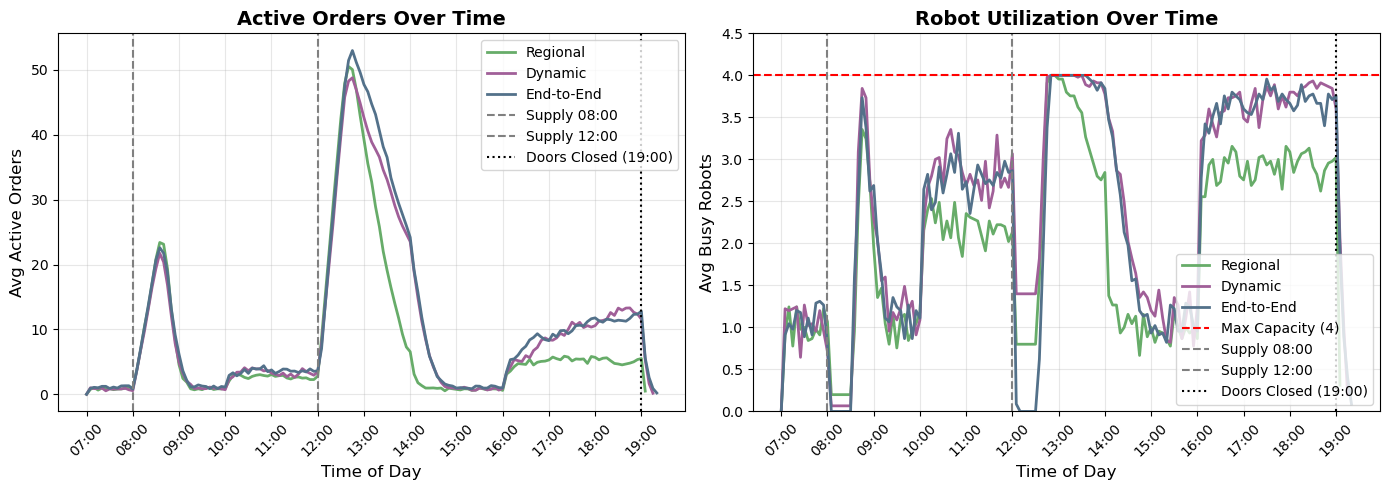

----------------------------------------------------------------------

Scenario 7: Changed Supply Times (10:00 & 14:00)
   - specialized  Cycle Time:  5.40 ± 0.33 mins  [ 5.07 ,  5.73]
   - dynamic      Cycle Time:  9.01 ± 0.95 mins  [ 8.06 ,  9.97]
   - end_to_end   Cycle Time:  8.48 ± 0.66 mins  [ 7.82 ,  9.13]
   --- Statistical Comparison (Paired T-test) ---
   specialized vs dynamic: Diff CI [-4.67 , -2.57] -> specialized is FASTER
   specialized vs end_to_end: Diff CI [-3.85 , -2.31] -> specialized is FASTER
   dynamic vs end_to_end: Diff CI [-0.51 ,  1.58] -> No significant diff
   -> Robustness check: PASSED

 מדדים מסכמים לתרחיש:


,חלופה,זמן שהייה (דקות),זמן סנכרון פנימי (דקות),ניצולת (%)
0,Alt 1 (Regional),5.40 ± 0.33,1.86 ± 0.15,40.10% ± 0.40%
1,Alt 2 (Dynamic),9.01 ± 0.95,0.81 ± 0.02,40.32% ± 0.40%
2,Alt 3 (End-to-End),8.48 ± 0.66,-,40.33% ± 0.45%


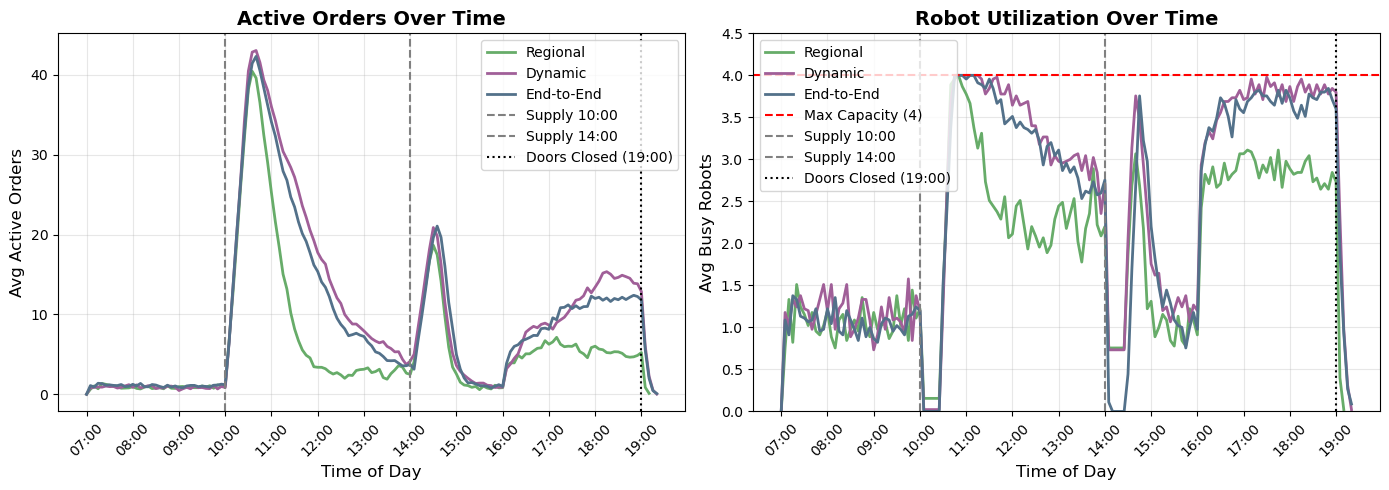

----------------------------------------------------------------------

Scenario 8: Changed Supply Times (07:00 & 18:00)
   - specialized  Cycle Time:  6.42 ± 0.25 mins  [ 6.17 ,  6.67]
   - dynamic      Cycle Time:  8.46 ± 0.58 mins  [ 7.88 ,  9.03]
   - end_to_end   Cycle Time:  8.07 ± 0.46 mins  [ 7.61 ,  8.53]
   --- Statistical Comparison (Paired T-test) ---
   specialized vs dynamic: Diff CI [-2.67 , -1.40] -> specialized is FASTER
   specialized vs end_to_end: Diff CI [-2.23 , -1.07] -> specialized is FASTER
   dynamic vs end_to_end: Diff CI [-0.41 ,  1.18] -> No significant diff
   -> Robustness check: PASSED

 מדדים מסכמים לתרחיש:


,חלופה,זמן שהייה (דקות),זמן סנכרון פנימי (דקות),ניצולת (%)
0,Alt 1 (Regional),6.42 ± 0.25,1.76 ± 0.12,40.46% ± 0.40%
1,Alt 2 (Dynamic),8.46 ± 0.58,0.78 ± 0.02,40.58% ± 0.44%
2,Alt 3 (End-to-End),8.07 ± 0.46,-,40.52% ± 0.46%


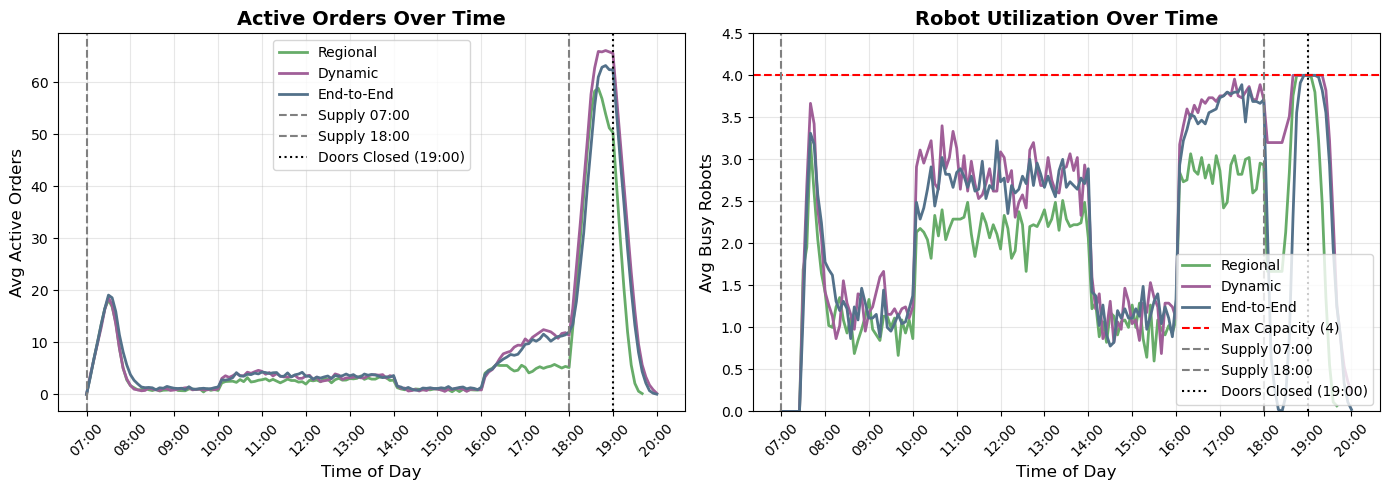

----------------------------------------------------------------------

Scenario 9: More Robots (8 instead of 4)
   - specialized  Cycle Time:  5.38 ± 0.35 mins  [ 5.03 ,  5.73]
   - dynamic      Cycle Time:  6.31 ± 0.35 mins  [ 5.96 ,  6.66]
   - end_to_end   Cycle Time:  6.47 ± 0.33 mins  [ 6.14 ,  6.80]
   --- Statistical Comparison (Paired T-test) ---
   specialized vs dynamic: Diff CI [-1.43 , -0.43] -> specialized is FASTER
   specialized vs end_to_end: Diff CI [-1.58 , -0.59] -> specialized is FASTER
   dynamic vs end_to_end: Diff CI [-0.60 ,  0.28] -> No significant diff
   -> Robustness check: PASSED

 מדדים מסכמים לתרחיש:


,חלופה,זמן שהייה (דקות),זמן סנכרון פנימי (דקות),ניצולת (%)
0,Alt 1 (Regional),5.38 ± 0.35,1.91 ± 0.18,20.03% ± 0.20%
1,Alt 2 (Dynamic),6.31 ± 0.35,1.35 ± 0.05,20.32% ± 0.24%
2,Alt 3 (End-to-End),6.47 ± 0.33,-,20.16% ± 0.18%


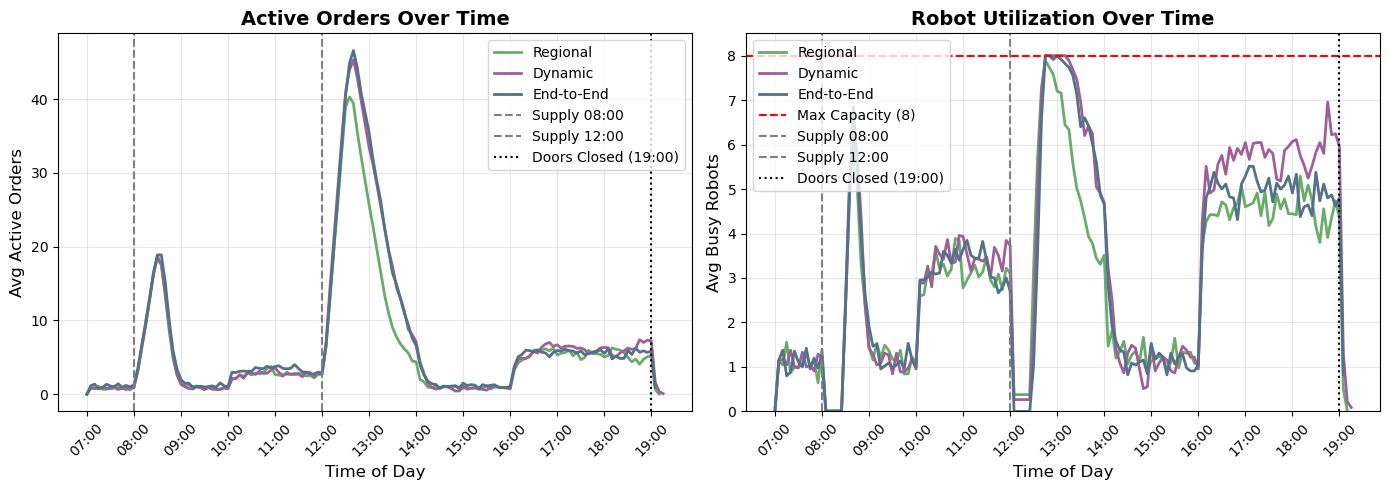

----------------------------------------------------------------------

Scenario 10: Low Load (-20% Arrivals)
   - specialized  Cycle Time:  4.45 ± 0.25 mins  [ 4.19 ,  4.70]
   - dynamic      Cycle Time:  5.16 ± 0.34 mins  [ 4.82 ,  5.50]
   - end_to_end   Cycle Time:  5.49 ± 0.33 mins  [ 5.16 ,  5.82]
   --- Statistical Comparison (Paired T-test) ---
   specialized vs dynamic: Diff CI [-1.13 , -0.30] -> specialized is FASTER
   specialized vs end_to_end: Diff CI [-1.45 , -0.64] -> specialized is FASTER
   dynamic vs end_to_end: Diff CI [-0.88 ,  0.21] -> No significant diff
   -> Robustness check: PASSED

 מדדים מסכמים לתרחיש:


,חלופה,זמן שהייה (דקות),זמן סנכרון פנימי (דקות),ניצולת (%)
0,Alt 1 (Regional),4.45 ± 0.25,1.17 ± 0.07,32.30% ± 0.43%
1,Alt 2 (Dynamic),5.16 ± 0.34,0.68 ± 0.02,32.32% ± 0.42%
2,Alt 3 (End-to-End),5.49 ± 0.33,-,31.91% ± 0.51%


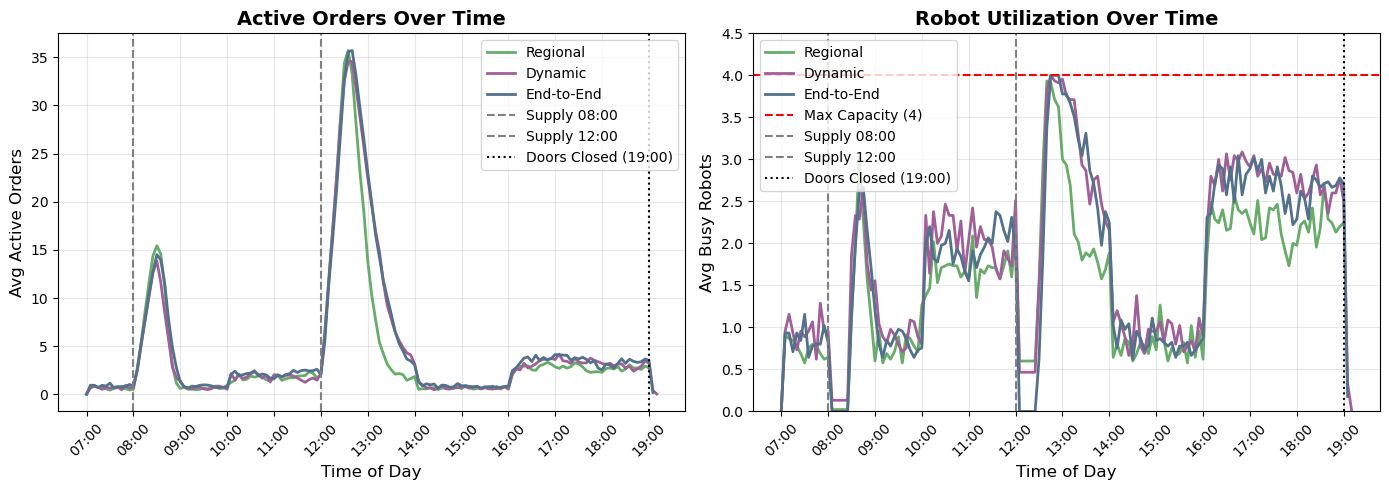

----------------------------------------------------------------------


In [11]:
# =========================================================
# ניתוח רגישות נקודתי
# # =========================================================
print("\n" + "="*60)
print(" 3. SENSITIVITY ANALYSIS")
print("="*60)

sensitivity_results = {
    'high_load':       {'specialized': [], 'dynamic': [], 'end_to_end': []},
    'slower_robots':   {'specialized': [], 'dynamic': [], 'end_to_end': []},
    'heavy_orders': {'specialized': [], 'dynamic': [], 'end_to_end': []},
    'robot_failure':   {'specialized': [], 'dynamic': [], 'end_to_end': []},
    'heavy_supply':    {'specialized': [], 'dynamic': [], 'end_to_end': []},
    'slow_supply':     {'specialized': [], 'dynamic': [], 'end_to_end': []},
    'changed_supply1':  {'specialized': [], 'dynamic': [], 'end_to_end': []},
    'changed_supply2':  {'specialized': [], 'dynamic': [], 'end_to_end': []},
    'More_Robots': {'specialized': [], 'dynamic': [], 'end_to_end': []},
    'low_load': {'specialized': [], 'dynamic': [], 'end_to_end': []}
}
sensitivity_utils = {k: {'specialized': [], 'dynamic': [], 'end_to_end': []} for k in sensitivity_results.keys()}
sensitivity_sync = {k: {'specialized': [], 'dynamic': [], 'end_to_end': []} for k in sensitivity_results.keys()}
sensitivity_queues = {k: {'specialized': [], 'dynamic': [], 'end_to_end': []} for k in sensitivity_results.keys()}
sensitivity_robots = {k: {'specialized': [], 'dynamic': [], 'end_to_end': []} for k in sensitivity_results.keys()}

# תרחיש 1: עומס לקוחות (+20% הגעות)
original_hourly_rates = HOURLY_RATES.copy()
original_max_lambda = MAX_LAMBDA_PER_MIN
# עדכון הפרמטרים
HOURLY_RATES = {
    (0, 3): original_hourly_rates[(0, 3)] * 1.2,
    (3, 7): original_hourly_rates[(3, 7)] * 1.2,
    (7, 9): original_hourly_rates[(7, 9)] * 1.2,
    (9, 12): original_hourly_rates[(9, 12)] * 1.2
}
MAX_LAMBDA_PER_MIN = max(HOURLY_RATES.values()) / 60.0
print("Running Scenario 1: High Load (+20% Arrivals)")
for mode in ['specialized', 'dynamic', 'end_to_end']:
    for _ in range(NUM_REPLICATIONS):
        env = simpy.Environment()
        pharmacy = PharmacySystem(env, mode=mode)
        env.run()
        
        if pharmacy.stat_cycle_times: 
            sensitivity_results['high_load'][mode].append(np.mean(pharmacy.stat_cycle_times))
            sensitivity_utils['high_load'][mode].append((pharmacy.total_busy_time / (SIM_TIME * NUM_ROBOTS)) * 100)
            if mode != 'end_to_end' and pharmacy.stat_internal_wait_times:
                sensitivity_sync['high_load'][mode].append(np.mean(pharmacy.stat_internal_wait_times))
            sensitivity_queues['high_load'][mode].append(pharmacy.history_active_orders)
            sensitivity_robots['high_load'][mode].append(pharmacy.history_busy_robots)
HOURLY_RATES = original_hourly_rates
MAX_LAMBDA_PER_MIN = original_max_lambda

# תרחיש 2: רובוטים איטיים יותר (+15% לזמן הליקוט)
ORIGINAL_PICK_MEAN = PICK_TIME_MEAN
PICK_TIME_MEAN = ORIGINAL_PICK_MEAN * 1.15
print("Running Scenario 2: Slower Robots (+15% Picking Time)")
for mode in ['specialized', 'dynamic', 'end_to_end']:
    for _ in range(NUM_REPLICATIONS):
        env = simpy.Environment()
        pharmacy = PharmacySystem(env, mode=mode)
        env.run()
        if pharmacy.stat_cycle_times: 
            sensitivity_results['slower_robots'][mode].append(np.mean(pharmacy.stat_cycle_times))
            sensitivity_utils['slower_robots'][mode].append((pharmacy.total_busy_time / (SIM_TIME * NUM_ROBOTS)) * 100)
            if mode != 'end_to_end' and pharmacy.stat_internal_wait_times:
                sensitivity_sync['slower_robots'][mode].append(np.mean(pharmacy.stat_internal_wait_times))
            sensitivity_queues['slower_robots'][mode].append(pharmacy.history_active_orders)
            sensitivity_robots['slower_robots'][mode].append(pharmacy.history_busy_robots)
PICK_TIME_MEAN = ORIGINAL_PICK_MEAN 


# תרחיש 3: שינוי פרופיל קנייה (הזמנות כבדות יותר)
ORIGINAL_PROBS = ORDER_SIZE_PROBS.copy()
ORDER_SIZE_PROBS = {1: 0.2, 2: 0.3, 3: 0.5} # הרוב קונים 3 תרופות!
print("Running Scenario 3: Heavier Customer Orders (More items)")
for mode in ['specialized', 'dynamic', 'end_to_end']:
    for _ in range(NUM_REPLICATIONS):
        env = simpy.Environment()
        pharmacy = PharmacySystem(env, mode=mode)
        env.run()
        if pharmacy.stat_cycle_times: 
            sensitivity_results['heavy_orders'][mode].append(np.mean(pharmacy.stat_cycle_times))
            sensitivity_utils['heavy_orders'][mode].append((pharmacy.total_busy_time / (SIM_TIME * NUM_ROBOTS)) * 100)
            if mode != 'end_to_end' and pharmacy.stat_internal_wait_times:
                sensitivity_sync['heavy_orders'][mode].append(np.mean(pharmacy.stat_internal_wait_times))
            sensitivity_queues['heavy_orders'][mode].append(pharmacy.history_active_orders)
            sensitivity_robots['heavy_orders'][mode].append(pharmacy.history_busy_robots)
ORDER_SIZE_PROBS = ORIGINAL_PROBS 


# תרחיש 4: השבתת רובוט (3 במקום 4)
ORIGINAL_ROBOTS = NUM_ROBOTS
NUM_ROBOTS = 3 
print("Running Scenario 4: Robot Failure (3 instead of 4)")
for mode in ['specialized', 'dynamic', 'end_to_end']:
    for _ in range(NUM_REPLICATIONS):
        env = simpy.Environment()
        pharmacy = PharmacySystem(env, mode=mode)
        env.run()
        if pharmacy.stat_cycle_times: 
            sensitivity_results['robot_failure'][mode].append(np.mean(pharmacy.stat_cycle_times))
            sensitivity_utils['robot_failure'][mode].append((pharmacy.total_busy_time / (SIM_TIME * NUM_ROBOTS)) * 100)
            if mode != 'end_to_end' and pharmacy.stat_internal_wait_times:
                sensitivity_sync['robot_failure'][mode].append(np.mean(pharmacy.stat_internal_wait_times))
            sensitivity_queues['robot_failure'][mode].append(pharmacy.history_active_orders)
            sensitivity_robots['robot_failure'][mode].append(pharmacy.history_busy_robots)
NUM_ROBOTS = ORIGINAL_ROBOTS 


# תרחיש 5: משאית סחורה כבדה יותר 
ORIGINAL_MIN_BOXES = SUPPLY_MIN_BOXES
ORIGINAL_MAX_BOXES = SUPPLY_MAX_BOXES
SUPPLY_MIN_BOXES = ORIGINAL_MIN_BOXES + 20
SUPPLY_MAX_BOXES = ORIGINAL_MAX_BOXES + 30
print("Running Scenario 5: Heavy Supply Truck (+ 20~50 boxes)")
for mode in ['specialized', 'dynamic', 'end_to_end']:
    for _ in range(NUM_REPLICATIONS):
        env = simpy.Environment()
        pharmacy = PharmacySystem(env, mode=mode)
        env.run()
        if pharmacy.stat_cycle_times: 
            sensitivity_results['heavy_supply'][mode].append(np.mean(pharmacy.stat_cycle_times))
            sensitivity_utils['heavy_supply'][mode].append((pharmacy.total_busy_time / (SIM_TIME * NUM_ROBOTS)) * 100)
            if mode != 'end_to_end' and pharmacy.stat_internal_wait_times:
                sensitivity_sync['heavy_supply'][mode].append(np.mean(pharmacy.stat_internal_wait_times))
            sensitivity_queues['heavy_supply'][mode].append(pharmacy.history_active_orders)
            sensitivity_robots['heavy_supply'][mode].append(pharmacy.history_busy_robots)
SUPPLY_MIN_BOXES = ORIGINAL_MIN_BOXES
SUPPLY_MAX_BOXES = ORIGINAL_MAX_BOXES


# תרחיש 6: פריקת סחורה איטית (הכפלת הקבוע)
ORIGINAL_SUPPLY_CONST = base_setup_time
base_setup_time = ORIGINAL_SUPPLY_CONST * 2
print("Running Scenario 6: Slower Unloading Time")
for mode in ['specialized', 'dynamic', 'end_to_end']:
    for _ in range(NUM_REPLICATIONS):
        env = simpy.Environment()
        pharmacy = PharmacySystem(env, mode=mode)
        env.run()
        if pharmacy.stat_cycle_times: 
            sensitivity_results['slow_supply'][mode].append(np.mean(pharmacy.stat_cycle_times))
            sensitivity_utils['slow_supply'][mode].append((pharmacy.total_busy_time / (SIM_TIME * NUM_ROBOTS)) * 100)
            if mode != 'end_to_end' and pharmacy.stat_internal_wait_times:
                sensitivity_sync['slow_supply'][mode].append(np.mean(pharmacy.stat_internal_wait_times))
            sensitivity_queues['slow_supply'][mode].append(pharmacy.history_active_orders)
            sensitivity_robots['slow_supply'][mode].append(pharmacy.history_busy_robots)

base_setup_time = ORIGINAL_SUPPLY_CONST

# תרחיש 7: שינוי שעות הפריקה (10:00 ו-14:00 במקום 08:00 ו-12:00)
ORIGINAL_SUPPLY_EVENTS = list(SUPPLY_EVENTS_MINUTES)
SUPPLY_EVENTS_MINUTES = [180, 420] # 3 שעות מתחילת היום (10:00) ו-7 שעות (14:00)
print("Running Scenario 7: Changed Supply Times (10:00 and 14:00)")
for mode in ['specialized', 'dynamic', 'end_to_end']:
    for _ in range(NUM_REPLICATIONS):
        env = simpy.Environment()
        pharmacy = PharmacySystem(env, mode=mode)
        env.run()
        if pharmacy.stat_cycle_times: 
            sensitivity_results['changed_supply1'][mode].append(np.mean(pharmacy.stat_cycle_times))
            sensitivity_utils['changed_supply1'][mode].append((pharmacy.total_busy_time / (SIM_TIME * NUM_ROBOTS)) * 100)
            if mode != 'end_to_end' and pharmacy.stat_internal_wait_times:
                sensitivity_sync['changed_supply1'][mode].append(np.mean(pharmacy.stat_internal_wait_times))
            sensitivity_queues['changed_supply1'][mode].append(pharmacy.history_active_orders)
            sensitivity_robots['changed_supply1'][mode].append(pharmacy.history_busy_robots)
SUPPLY_EVENTS_MINUTES = ORIGINAL_SUPPLY_EVENTS

# תרחיש 8: שינוי שעות הפריקה (07:00 ו-18:00 במקום 08:00 ו-12:00)
ORIGINAL_SUPPLY_EVENTS = list(SUPPLY_EVENTS_MINUTES)
SUPPLY_EVENTS_MINUTES = [0, 660] 
print("Running Scenario 8: Changed Supply Times (07:00 and 18:00)")
for mode in ['specialized', 'dynamic', 'end_to_end']:
    for _ in range(NUM_REPLICATIONS):
        env = simpy.Environment()
        pharmacy = PharmacySystem(env, mode=mode)
        env.run()
        if pharmacy.stat_cycle_times: 
            sensitivity_results['changed_supply2'][mode].append(np.mean(pharmacy.stat_cycle_times))
            sensitivity_utils['changed_supply2'][mode].append((pharmacy.total_busy_time / (SIM_TIME * NUM_ROBOTS)) * 100)
            if mode != 'end_to_end' and pharmacy.stat_internal_wait_times:
                sensitivity_sync['changed_supply2'][mode].append(np.mean(pharmacy.stat_internal_wait_times))
            sensitivity_queues['changed_supply2'][mode].append(pharmacy.history_active_orders)
            sensitivity_robots['changed_supply2'][mode].append(pharmacy.history_busy_robots)
SUPPLY_EVENTS_MINUTES = ORIGINAL_SUPPLY_EVENTS

# תרחיש 9: הוספת רובוטים חדשים
ORIGINAL_ROBOTS = NUM_ROBOTS
NUM_ROBOTS = 8 
print("Running Scenario 9: More Robots (8 instead of 4)")
for mode in ['specialized', 'dynamic', 'end_to_end']:
    for _ in range(NUM_REPLICATIONS):
        env = simpy.Environment()
        pharmacy = PharmacySystem(env, mode=mode)
        env.run()
        if pharmacy.stat_cycle_times: 
            sensitivity_results['More_Robots'][mode].append(np.mean(pharmacy.stat_cycle_times))
            sensitivity_utils['More_Robots'][mode].append((pharmacy.total_busy_time / (SIM_TIME * NUM_ROBOTS)) * 100)
            if mode != 'end_to_end' and pharmacy.stat_internal_wait_times:
                sensitivity_sync['More_Robots'][mode].append(np.mean(pharmacy.stat_internal_wait_times))
            sensitivity_queues['More_Robots'][mode].append(pharmacy.history_active_orders)
            sensitivity_robots['More_Robots'][mode].append(pharmacy.history_busy_robots)
NUM_ROBOTS = ORIGINAL_ROBOTS 


# תרחיש 10: מיעוט לקוחות (-20% הגעות)
original_hourly_rates = HOURLY_RATES.copy()
original_max_lambda = MAX_LAMBDA_PER_MIN
# עדכון הפרמטרים
HOURLY_RATES = {
    (0, 3): original_hourly_rates[(0, 3)] * 0.8,
    (3, 7): original_hourly_rates[(3, 7)] * 0.8,
    (7, 9): original_hourly_rates[(7, 9)] * 0.8,
    (9, 12): original_hourly_rates[(9, 12)] * 0.8
}
MAX_LAMBDA_PER_MIN = max(HOURLY_RATES.values()) / 60.0
print("Running Scenario 10: Low Load (-20% Arrivals)")
for mode in ['specialized', 'dynamic', 'end_to_end']:
    for _ in range(NUM_REPLICATIONS):
        env = simpy.Environment()
        pharmacy = PharmacySystem(env, mode=mode)
        env.run()
        
        if pharmacy.stat_cycle_times: 
            sensitivity_results['low_load'][mode].append(np.mean(pharmacy.stat_cycle_times))
            sensitivity_utils['low_load'][mode].append((pharmacy.total_busy_time / (SIM_TIME * NUM_ROBOTS)) * 100)
            if mode != 'end_to_end' and pharmacy.stat_internal_wait_times:
                sensitivity_sync['low_load'][mode].append(np.mean(pharmacy.stat_internal_wait_times))
            sensitivity_queues['low_load'][mode].append(pharmacy.history_active_orders)
            sensitivity_robots['low_load'][mode].append(pharmacy.history_busy_robots)
HOURLY_RATES = original_hourly_rates
MAX_LAMBDA_PER_MIN = original_max_lambda



print("\n" + "="*60)
print(" SENSITIVITY ANALYSIS RESULTS (Cycle Time)")
print("="*60)

scenarios = [
    ('high_load',       'Scenario 1: High Load (+20% Arrivals)'),
    ('slower_robots',   'Scenario 2: Slower Robots (+15% Picking Time)'),
    ('heavy_orders', 'Scenario 3: Heavier Orders (More items)'),
    ('robot_failure',   'Scenario 4: 3 Robots (Failure)'),
    ('heavy_supply',    'Scenario 5: Heavy Truck (More boxes)'),
    ('slow_supply',     'Scenario 6: Slow Unloading'),
    ('changed_supply1',  'Scenario 7: Changed Supply Times (10:00 & 14:00)'),
    ('changed_supply2',  'Scenario 8: Changed Supply Times (07:00 & 18:00)'),
    ('More_Robots', 'Scenario 9: More Robots (8 instead of 4)'),
    ('low_load', 'Scenario 10: Low Load (-20% Arrivals)')

]

baseline_winner = find_statistical_winner(results)
print(f"\nStatistical Winner identified from Baseline: {baseline_winner}")

for dict_key, title in scenarios:
    print(f"\n{title}")
    for mode in ['specialized', 'dynamic', 'end_to_end']:
        if len(sensitivity_results[dict_key][mode]) > 0:
            m, hw = calc_ci(sensitivity_results[dict_key][mode])
            print(f"   - {mode: <12} Cycle Time: {m:5.2f} ± {hw:.2f} mins  [{m-hw:5.2f} , {m+hw:5.2f}]")

# מבחן T זוגי (Paired) בין כל החלופות בתרחיש הרגישות הנוכחי
    print("   --- Statistical Comparison (Paired T-test) ---")
    modes = ['specialized', 'dynamic', 'end_to_end']
    for i in range(len(modes)):
        for j in range(i + 1, len(modes)):
            m1, m2 = modes[i], modes[j]
            # מבחן זוגי: חיסור איבר-איבר לאותה ריצה (Replication)
            diffs = np.array(sensitivity_results[dict_key][m1]) - np.array(sensitivity_results[dict_key][m2])
            d_m, d_hw = calc_ci(diffs)
            
            status = "No significant diff"
            if d_m + d_hw < 0: status = f"{m1} is FASTER"
            elif d_m - d_hw > 0: status = f"{m2} is FASTER"
            
            print(f"   {m1} vs {m2}: Diff CI [{d_m-d_hw:5.2f} , {d_m+d_hw:5.2f}] -> {status}")
            
    # בדיקת חוסן של החלופה המנצחת (אם יש כזו)
    if baseline_winner:
        is_robust = True
        for other in [m for m in modes if m != baseline_winner]:
            diffs = np.array(sensitivity_results[dict_key][baseline_winner]) - np.array(sensitivity_results[dict_key][other])
            d_m, d_hw = calc_ci(diffs)
            if d_m - d_hw > 0: # אם חלופה אחרת הפכה למהירה יותר
                is_robust = False
        print(f"   -> Robustness check: {'PASSED' if is_robust else 'FAILED (Winner changed!)'}")

    # --- 1. יצירת והצגת טבלת המדדים לתרחיש הנוכחי ---
    scenario_table = []
    title_map = {'specialized': 'Alt 1 (Regional)', 'dynamic': 'Alt 2 (Dynamic)', 'end_to_end': 'Alt 3 (End-to-End)'}
    
    for m in ['specialized', 'dynamic', 'end_to_end']:
        m_cycle, hw_cycle = calc_ci(sensitivity_results[dict_key][m])
        m_util, hw_util = calc_ci(sensitivity_utils[dict_key][m])
        
        if m in sensitivity_sync[dict_key] and len(sensitivity_sync[dict_key][m]) > 0:
            m_sync, hw_sync = calc_ci(sensitivity_sync[dict_key][m])
            sync_str = f"{m_sync:.2f} ± {hw_sync:.2f}"
        else:
            sync_str = "-"
            
        scenario_table.append({
            'חלופה': title_map[m],
            'זמן שהייה (דקות)': f"{m_cycle:.2f} ± {hw_cycle:.2f}",
            'זמן סנכרון פנימי (דקות)': sync_str,
            'ניצולת (%)': f"{m_util:.2f}% ± {hw_util:.2f}%"
        })
    
    print(f"\n מדדים מסכמים לתרחיש:")
    display(pd.DataFrame(scenario_table))

    # שרטוט גרפים (ניצולת ועומס) לתרחיש הנוכחי
    
    # נמצא את המערך הארוך ביותר עבור התרחיש הנוכחי (dict_key)
    max_len_all = max(
        max((len(arr) for arr in sensitivity_queues[dict_key]['specialized']), default=0),
        max((len(arr) for arr in sensitivity_queues[dict_key]['dynamic']), default=0),
        max((len(arr) for arr in sensitivity_queues[dict_key]['end_to_end']), default=0)
    )
    
    if max_len_all > 0:
        extended_time_axis = np.arange(max_len_all) * 5.0 / 60.0 # קפיצות של 5 דקות

    #  פרמטרים דינמיים לגרפים לפי התרחיש 
        current_robots = 4 # ברירת מחדל
        current_supply = [1.0, 5.0] # ברירת מחדל: שעה 1 (08:00) ושעה 5 (12:00)

        if dict_key == 'robot_failure': current_robots = 3
        elif dict_key == 'More_Robots': current_robots = 8
            
        if dict_key == 'changed_supply1': current_supply = [3.0, 7.0] # 10:00 ו-14:00
        elif dict_key == 'changed_supply2': current_supply = [0.0, 11.0] # 07:00 ו-18:00

        # חישוב ממוצעים עם הפונקציה pad_with_zeros שלך
        mean_active_specialized = np.mean(pad_with_zeros(sensitivity_queues[dict_key]['specialized']), axis=0) 
        mean_active_dynamic = np.mean(pad_with_zeros(sensitivity_queues[dict_key]['dynamic']), axis=0) 
        mean_active_end_to_end = np.mean(pad_with_zeros(sensitivity_queues[dict_key]['end_to_end']), axis=0) 

        mean_robots_specialized = np.mean(pad_with_zeros(sensitivity_robots[dict_key]['specialized']), axis=0) 
        mean_robots_dynamic = np.mean(pad_with_zeros(sensitivity_robots[dict_key]['dynamic']), axis=0) 
        mean_robots_end_to_end = np.mean(pad_with_zeros(sensitivity_robots[dict_key]['end_to_end']), axis=0) 

        # טיפול בתוויות ציר X
        tick_positions = np.arange(0, int(max(extended_time_axis))+1, 1)
        tick_labels = [f"{int((7+h) % 24):02d}:00" for h in tick_positions]

        plt.figure(figsize=(14, 5))

        # גרף עומס ממוצע לאורך שעות היום
        plt.subplot(1, 2, 1)
        plt.plot(extended_time_axis[:len(mean_active_specialized)], mean_active_specialized, color='#67AC69', linewidth=2, label='Regional')
        plt.plot(extended_time_axis[:len(mean_active_dynamic)], mean_active_dynamic, color='#A05F98', linewidth=2, label='Dynamic')
        plt.plot(extended_time_axis[:len(mean_active_end_to_end)], mean_active_end_to_end, color='#53718A', linewidth=2, label='End-to-End')

        plt.axvline(x=current_supply[0], color='gray', linestyle='--', label=f'Supply {int(7+current_supply[0]):02d}:00')
        plt.axvline(x=current_supply[1], color='gray', linestyle='--', label=f'Supply {int(7+current_supply[1]):02d}:00')
        plt.axvline(x=12.0, color='black', linestyle=':', label='Doors Closed (19:00)')
    
        plt.title("Active Orders Over Time", fontsize=14, fontweight='bold')
        plt.xlabel("Time of Day", fontsize=12)
        plt.ylabel("Avg Active Orders", fontsize=12)
        plt.xticks(tick_positions, tick_labels, rotation=45)
        plt.legend()
        plt.grid(True, alpha=0.3)

        # גרף ניצולת בזמן אמת
        plt.subplot(1, 2, 2)
        plt.plot(extended_time_axis[:len(mean_robots_specialized)], mean_robots_specialized, color='#67AC69', linewidth=2, label='Regional')
        plt.plot(extended_time_axis[:len(mean_robots_dynamic)], mean_robots_dynamic, color='#A05F98', linewidth=2, label='Dynamic')
        plt.plot(extended_time_axis[:len(mean_robots_end_to_end)], mean_robots_end_to_end, color='#53718A', linewidth=2, label='End-to-End')

        plt.axhline(y=current_robots, color='red', linestyle='--', label=f'Max Capacity ({current_robots})')
        plt.axvline(x=current_supply[0], color='gray', linestyle='--', label=f'Supply {int(7+current_supply[0]):02d}:00')
        plt.axvline(x=current_supply[1], color='gray', linestyle='--', label=f'Supply {int(7+current_supply[1]):02d}:00')
        plt.axvline(x=12.0, color='black', linestyle=':', label='Doors Closed (19:00)')
    
        plt.title("Robot Utilization Over Time", fontsize=14, fontweight='bold')
        plt.xlabel("Time of Day", fontsize=12)
        plt.ylabel("Avg Busy Robots", fontsize=12)
        plt.ylim(0, current_robots + 0.5) # מעדכן את תקרת הגרף למספר הרובוטים הנוכחי
        plt.xticks(tick_positions, tick_labels, rotation=45)

        plt.legend()
        plt.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()
        print("-" * 70)